# Análise quantitativa com os microdados do ENEM 2023 — notebook do curso

**Curso:** Métodos Quantitativos / Tópicos de Análise Quantitativa (CAEO/CAO — CBMDF)
**Autor:** André T. Campos

Este notebook acompanha a palestra módulo a módulo. Em cada etapa aparece primeiro o **prompt** que um analista daria a uma IA (numa caixa *IA*), depois os **comandos** que esse prompt deve produzir e, por fim, a **verificação independente**: o que o analista confere antes de confiar no resultado.

| Módulo | Pergunta | O que se faz |
|---|---|---|
| 1 | Como decidir com dados e usar IA com método? | conhecer a base do ENEM 2023 e como se chegou à base reduzida |
| 2 | Quem está nos dados e quem fica fora da medição? | análise exploratória e limpeza: nulos, escola, zeros, base de análise |
| 3 | Quanto as notas diferem entre os grupos, mostrado com honestidade? | estatística descritiva: Matemática por tipo de escola, sexo, cor/raça, gráfico honesto |
| 4 | Qual condicional estamos lendo? | probabilidade: condicional, binomial, normal, Teorema Central do Limite |
| 5 | Com uma amostra, quão perto chegamos das diferenças reais? | amostragem: erro padrão, intervalo de confiança, tamanho da amostra, vieses |
| 6 | As diferenças são reais? E importam? | três testes completos: t de Welch, ANOVA e qui-quadrado |
| 7 | Quanto de cada fator permanece quando controlamos os outros? | correlação e regressão |

**Fio condutor:** *quanto as notas do ENEM variam com a **renda**, o **tipo de escola**, o **território**, o **sexo** e a **cor/raça**? De que tamanho são essas diferenças, quem fica fora da medição, e com que segurança podemos afirmar, sem confundir associação com causa?* Alguns exemplos ficam fora do fio de propósito (o chute na prova, MT ~ CN, treineiros, Anscombe): servem para introduzir conceitos.

**Fonte dos dados:** INEP, Microdados do ENEM 2023 — <https://www.gov.br/inep/pt-br/acesso-a-informacao/dados-abertos/microdados/enem>. Cor/raça é **autodeclarada**; os recortes por cor/raça são nacionais.

**Reprodutibilidade:** cada seção que sorteia cria o seu próprio gerador com a semente `2023`. Assim, uma seção dá sempre o mesmo resultado, qualquer que seja a ordem em que as outras foram executadas.

---
# Preparação

Bibliotecas, estilo dos gráficos, funções usadas em todo o notebook e os rótulos do dicionário.

In [1]:
# Bibliotecas (todas disponíveis no Google Colab)
import os
import sys
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import statsmodels
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.power import TTestIndPower, GofChisquarePower
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 140)

SEMENTE = 2023    # semente única do curso; cada seção que sorteia cria seu gerador com ela

In [2]:
# Estilo dos gráficos: títulos que dizem a conclusão, eixos rotulados, sem 3D, paleta fixa
AZUL, LARANJA, VERDE, CINZA, VERMELHO = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984', '#e34948'
mpl.rcParams.update({
    'figure.figsize': (9, 5), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelsize': 11, 'legend.frameon': False,
    'axes.prop_cycle': mpl.cycler(color=[AZUL, LARANJA, VERDE]),
})

# Pasta de saída das figuras (para os slides). No Colab, é criada na pasta atual.
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
SAIDA = RAIZ / 'saida' / 'curso'
SAIDA.mkdir(parents=True, exist_ok=True)

def salvar(fig, nome):
    # Salva a figura em saida/curso/ para uso nos slides
    fig.savefig(SAIDA / f'{nome}.png', dpi=200, bbox_inches='tight')

def br(x, casas=1):
    # Formata número no padrão brasileiro: 1.234,5
    return f'{x:,.{casas}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')

def fmt_p(p):
    return '< 0,001' if p < 0.001 else br(p, 3)

In [3]:
# Funções estatísticas usadas em todo o notebook (escritas à mão para que se veja a fórmula)

def ic_media(x, conf=0.95):
    # IC da média pela t de Student: média ± t * S/raiz(n)
    x = np.asarray(x, dtype=float)
    n, m = len(x), x.mean()
    ep = x.std(ddof=1) / np.sqrt(n)
    t = stats.t.ppf((1 + conf) / 2, n - 1)
    return m, m - t * ep, m + t * ep

def d_cohen(a, b):
    # d de Cohen: diferença de médias / desvio padrão combinado
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    na, nb = len(a), len(b)
    sp = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    return (a.mean() - b.mean()) / sp

def magnitude(d):
    # Convenções de Cohen (1988) — referência, não regra de decisão
    d = abs(d)
    return 'desprezível' if d < 0.2 else 'pequeno' if d < 0.5 else 'médio' if d < 0.8 else 'grande'

def comparar(a, b, nome_a='A', nome_b='B'):
    # Teste t de Welch + IC da diferença + d de Cohen: as três coisas que sempre se reportam
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    r = stats.ttest_ind(a, b, equal_var=False)
    ic = r.confidence_interval(0.95)
    d = d_cohen(a, b)
    return pd.Series({'grupo A': nome_a, 'grupo B': nome_b, 'n A': len(a), 'n B': len(b),
                      'média A': a.mean(), 'média B': b.mean(), 'diferença (A−B)': a.mean() - b.mean(),
                      'IC95% inf': ic.low, 'IC95% sup': ic.high, 't': r.statistic, 'p': r.pvalue,
                      'd de Cohen': d, 'magnitude': magnitude(d)})

def relatar(res, unidade='pontos'):
    # Frase-padrão de relatório: efeito + IC + p + tamanho do efeito
    print(f"{res['grupo A']} − {res['grupo B']}: diferença de {br(res['diferença (A−B)'])} {unidade} "
          f"(IC95% [{br(res['IC95% inf'])}; {br(res['IC95% sup'])}]); "
          f"d = {br(res['d de Cohen'], 2)} (efeito {res['magnitude']}); p {fmt_p(res['p'])}; "
          f"n = {br(res['n A'], 0)} e {br(res['n B'], 0)}.")

def classificar(lo, hi, margem):
    # Leitura de relevância: compara o IC95% da diferença com a margem de relevância fixada antes
    if lo > margem or hi < -margem:
        return 'diferença relevante'
    if -margem < lo and hi < margem:
        return 'diferente, mas irrelevante' if (lo > 0 or hi < 0) else 'equivalente na prática'
    if lo > 0 or hi < 0:
        return 'diferente; relevância incerta'
    return 'inconclusivo'

def eta2(y, grupos):
    # Eta ao quadrado: fração da variação total associada aos grupos (SQ entre / SQ total)
    df_ = pd.DataFrame({'y': np.asarray(y, dtype=float), 'g': np.asarray(grupos)})
    media = df_.y.mean()
    g = df_.groupby('g').y.agg(['count', 'mean'])
    sq_entre = (g['count'] * (g['mean'] - media) ** 2).sum()
    sq_total = ((df_.y - media) ** 2).sum()
    return sq_entre / sq_total

**Rótulos do dicionário.** Os códigos abaixo foram copiados do **Dicionário de Microdados do ENEM 2023** (planilha do INEP). Não deduza o significado de um código pelo nome da coluna: `TP_ESCOLA = 1` é "Não respondeu", e não "pública".

In [4]:
ROT_SEXO = {'F': 'Feminino', 'M': 'Masculino'}
ROT_COR = {0: 'Não declarado', 1: 'Branca', 2: 'Preta', 3: 'Parda', 4: 'Amarela', 5: 'Indígena', 6: 'Não dispõe da informação'}
ROT_CONCLUSAO = {1: 'Já concluiu o EM', 2: 'Concluirá o EM em 2023', 3: 'Concluirá o EM após 2023', 4: 'Não concluiu e não está cursando'}
ROT_ESCOLA = {1: 'Não respondeu', 2: 'Pública', 3: 'Privada'}
ROT_DEPENDENCIA = {1: 'Federal', 2: 'Estadual', 3: 'Municipal', 4: 'Privada'}
ROT_PRESENCA = {0: 'Faltou', 1: 'Presente', 2: 'Eliminado'}
ROT_STATUS_RED = {1: 'Sem problemas', 2: 'Anulada', 3: 'Cópia do texto motivador', 4: 'Em branco', 6: 'Fuga ao tema',
                  7: 'Não atendimento ao tipo textual', 8: 'Texto insuficiente', 9: 'Parte desconectada'}
# Q001 (pai) e Q002 (mãe): até que série estudou
ROT_INSTRUCAO = {'A': 'Nunca estudou', 'B': 'Não completou o 5º ano', 'C': '5º ano, sem o 9º ano',
                 'D': '9º ano, sem o EM', 'E': 'EM, sem faculdade', 'F': 'Faculdade, sem pós',
                 'G': 'Pós-graduação', 'H': 'Não sei'}
# Q006: renda mensal da família (17 faixas ordinais, A a Q; salário mínimo de 2023 = R$ 1.320)
FAIXAS_RENDA = list('ABCDEFGHIJKLMNOPQ')
ROT_RENDA = {'A': 'Nenhuma renda', 'B': 'até 1.320', 'C': '1.320–1.980', 'D': '1.980–2.640', 'E': '2.640–3.300',
             'F': '3.300–3.960', 'G': '3.960–5.280', 'H': '5.280–6.600', 'I': '6.600–7.920', 'J': '7.920–9.240',
             'K': '9.240–10.560', 'L': '10.560–11.880', 'M': '11.880–13.200', 'N': '13.200–15.840',
             'O': '15.840–19.800', 'P': '19.800–26.400', 'Q': 'acima de 26.400'}
# Agrupamento em 4 faixas (Módulos 6 e 7)
RENDA_4 = {**dict.fromkeys('AB', '1) até R$ 1.320'), **dict.fromkeys('CDE', '2) R$ 1.320–3.300'),
           **dict.fromkeys('FGH', '3) R$ 3.300–6.600'), **dict.fromkeys('IJKLMNOPQ', '4) acima de R$ 6.600')}

AREAS = ['CN', 'CH', 'LC', 'MT']
NOTAS = ['NU_NOTA_CN', 'NU_NOTA_CH', 'NU_NOTA_LC', 'NU_NOTA_MT', 'NU_NOTA_REDACAO']
NOME_NOTA = {'NU_NOTA_CN': 'Ciências da Natureza', 'NU_NOTA_CH': 'Ciências Humanas', 'NU_NOTA_LC': 'Linguagens',
             'NU_NOTA_MT': 'Matemática', 'NU_NOTA_REDACAO': 'Redação'}

---
# Módulo 1 — A base do ENEM 2023 e o protocolo de IA

O protocolo de IA do curso tem 7 regras: (1) pergunta e hipótese antes dos dados; (2) não enviar dados sensíveis; (3) pedir código, não números; (4) contexto completo no prompt; (5) pedir premissas e limitações; (6) verificar de forma independente; (7) registrar tudo. Todos os prompts deste notebook seguem o mesmo molde: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**.

## 1.1 O que o INEP publica

Os microdados do ENEM 2023 vêm num pacote de **1,7 GB** baixado do portal do INEP:

| Arquivo | Conteúdo |
|---|---|
| `DADOS/MICRODADOS_ENEM_2023.csv` | **3.933.955 linhas** (uma por inscrito) e **76 colunas**; separador `;`, codificação ISO-8859-1 (latin-1) |
| `DADOS/ITENS_PROVA_2023.csv` | 5.550 itens das provas, com gabarito e parâmetros da TRI |
| `DICIONÁRIO/Dicionário_Microdados_Enem_2023.xlsx` | significado de cada coluna e de cada código |
| `LEIA-ME E DOCUMENTOS TÉCNICOS/` | documentação técnica do INEP |

As 76 colunas cobrem: o participante (faixa etária, sexo, cor/raça, situação de conclusão do ensino médio, treineiro), a escola (só para concluintes de 2023), o local de prova, a presença e as notas das quatro provas objetivas e da redação, as respostas e os gabaritos de cada item, e o questionário socioeconômico (Q001 a Q025).

**Três problemas práticos** para usar esse arquivo em aula: (1) 1,7 GB não cabe com folga na memória de um computador comum nem no Google Colab gratuito, se lido com `pd.read_csv`; (2) as colunas de respostas (`TX_RESPOSTAS_*`, `TX_GABARITO_*`) são longas sequências de letras e quase triplicam o tamanho; (3) a aula usa só 25 colunas.

**O que fizemos** (scripts `src/converter_parquet.py` e `src/gerar_base_aula.py` do repositório):

1. CSV (1,7 GB) → **Parquet completo** (107 MB), sem as colunas de respostas e gabaritos. O Parquet é um formato **colunar e comprimido**: lê só as colunas pedidas, já com os tipos certos.
2. Parquet completo → **base reduzida** `enem2023_aula.parquet` (55 MB): as 25 colunas da aula, **todos os 3.933.955 inscritos** (inclusive os faltosos, porque quem falta é tema do Módulo 5) e **sem o número de inscrição** (`NU_INSCRICAO`), que não é usado em nenhuma análise.

A base reduzida está publicada como anexo da *Release* `base-v1` do repositório no GitHub, e é ela que este notebook lê.

### IA — Prompt da redução da base

O prompt abaixo leva aos dois scripts que produziram a base da aula. Ele é um exemplo do protocolo: pede código, dá o contexto (formato, codificação, colunas), diz o que **não** fazer e pede a lista de conferência. No lugar de [colar a lista de colunas] vão os 25 nomes da lista `COLUNAS` do código abaixo.

```text
Papel: Você é um engenheiro de dados que escreve código reprodutível.

Contexto: Microdados do ENEM 2023 (INEP): CSV de 1,7 GB, separador ";", latin-1, 76 colunas, uma linha por inscrito; 8 colunas (TX_RESPOSTAS_* e TX_GABARITO_*) guardam respostas e gabaritos. A base vai para alunos no Colab.

Pergunta: Como gerar uma base pequena, que caiba no Colab, sem perder nenhum inscrito e com só as colunas que a aula usa?

Tarefa: (1) Converta o CSV em Parquet com DuckDB, sem carregar o arquivo no pandas, sem as colunas TX_RESPOSTAS_* e TX_GABARITO_*, com compressão zstd. (2) Desse Parquet, grave outro só com as 25 colunas da lista abaixo. (3) Imprima o número de linhas, o de colunas e o tamanho do arquivo em MB. [colar a lista de colunas]

Restrições: Não filtre nenhuma linha: os faltosos ficam. Não renomeie nem recodifique colunas. NU_INSCRICAO não entra. Os caminhos vêm de variáveis de ambiente, não escritos no código. Não envio dados, só os nomes das colunas.

Formato: Dois scripts curtos e comentados em português; depois, uma lista do que eu devo conferir para saber que a conversão não perdeu nada.
```

**Verificação independente** (o analista faz depois de rodar o código da IA):
- O número de linhas da base reduzida é igual ao do CSV oficial (3.933.955)?
- São exatamente as 25 colunas pedidas, e NU_INSCRICAO não está entre elas?
- O CSV foi lido com `encoding=latin-1` e `delim=";"`? (sem isso, acentos e colunas saem errados)
- Os tipos fazem sentido: notas numéricas, Q001–Q006 como texto (letras), códigos TP_* como inteiros?
- Os nulos das notas continuam nulos (não viraram zero)?

**O código que esse prompt produz** (é o que está em `src/converter_parquet.py` e `src/gerar_base_aula.py`). **Não execute aqui**: ele precisa do pacote de 1,7 GB do INEP. Fica como registro de como a base foi feita.

```python
import os
from pathlib import Path
import duckdb

MICRODADOS = Path(os.environ['MQ_MICRODADOS'])      # pasta do pacote do INEP
DADOS = Path(os.environ['MQ_DADOS'])                # pasta onde gravar os Parquets
CSV = MICRODADOS / 'DADOS' / 'MICRODADOS_ENEM_2023.csv'
COMPLETO = DADOS / 'enem2023.parquet'
REDUZIDA = DADOS / 'enem2023_aula.parquet'

con = duckdb.connect()

# Passo 1: CSV (latin-1, ';') -> Parquet, sem as colunas de respostas e gabaritos.
# O DuckDB lê o CSV em blocos: o arquivo nunca é carregado inteiro na memória.
con.execute(f"""
    COPY (
        SELECT * EXCLUDE (TX_RESPOSTAS_CN, TX_RESPOSTAS_CH, TX_RESPOSTAS_LC, TX_RESPOSTAS_MT,
                          TX_GABARITO_CN, TX_GABARITO_CH, TX_GABARITO_LC, TX_GABARITO_MT)
        FROM read_csv('{CSV.as_posix()}', delim=';', encoding='latin-1', header=true, sample_size=-1)
    ) TO '{COMPLETO.as_posix()}' (FORMAT parquet, COMPRESSION zstd)
""")

# Passo 2: só as 25 colunas da aula; todas as linhas (faltosos inclusive); sem NU_INSCRICAO
COLUNAS = [
    'TP_FAIXA_ETARIA', 'TP_SEXO', 'TP_COR_RACA', 'TP_ST_CONCLUSAO', 'TP_ESCOLA', 'IN_TREINEIRO',   # participante
    'SG_UF_ESC', 'TP_DEPENDENCIA_ADM_ESC',                                                         # escola
    'CO_MUNICIPIO_PROVA', 'NO_MUNICIPIO_PROVA', 'SG_UF_PROVA',                                     # local da prova
    'TP_PRESENCA_CN', 'TP_PRESENCA_CH', 'TP_PRESENCA_LC', 'TP_PRESENCA_MT',                        # presença
    'NU_NOTA_CN', 'NU_NOTA_CH', 'NU_NOTA_LC', 'NU_NOTA_MT', 'TP_STATUS_REDACAO', 'NU_NOTA_REDACAO',  # notas
    'Q001', 'Q002', 'Q005', 'Q006',                                                                # questionário
]
con.execute(f"""
    COPY (SELECT {', '.join(COLUNAS)} FROM '{COMPLETO.as_posix()}')
    TO '{REDUZIDA.as_posix()}' (FORMAT parquet, COMPRESSION zstd)
""")

# Conferência
n = con.sql(f"SELECT count(*) FROM '{REDUZIDA.as_posix()}'").fetchone()[0]
print(f'{n:,} linhas | {len(COLUNAS)} colunas | {REDUZIDA.stat().st_size / 1e6:.1f} MB')
```

## 1.2 Leitura da base reduzida

**No Colab**, o notebook baixa a base da *Release* do repositório (`URL_BASE`). Localmente, lê o arquivo da pasta indicada na variável de ambiente `MQ_DADOS` ou, na falta dela, de `dados/` na raiz do projeto. A leitura do Parquet leva segundos.

In [5]:
ARQUIVO_LOCAL = Path(os.environ.get('MQ_DADOS', RAIZ / 'dados')) / 'enem2023_aula.parquet'
URL_BASE = 'https://github.com/atc857/metodos_quanti/releases/download/base-v1/enem2023_aula.parquet'
FONTE = ARQUIVO_LOCAL if ARQUIVO_LOCAL.exists() else URL_BASE

insc = pd.read_parquet(FONTE)   # uma linha por INSCRITO
print(f'{br(len(insc), 0)} linhas × {insc.shape[1]} colunas')

3.933.955 linhas × 25 colunas


In [6]:
# Registro da execução (regra 7 do protocolo)
print('Executado em:', datetime.now().strftime('%d/%m/%Y %H:%M'))
print('Python', sys.version.split()[0], '| pandas', pd.__version__, '| numpy', np.__version__,
      '| scipy', scipy.__version__, '| statsmodels', statsmodels.__version__)
print('Semente:', SEMENTE, '| Fonte:', 'arquivo local' if FONTE == ARQUIVO_LOCAL else URL_BASE)

Executado em: 25/10/2026 16:36
Python 3.14.7 | pandas 3.0.6 | numpy 2.5.3 | scipy 1.18.1 | statsmodels 0.15.0
Semente: 2023 | Fonte: arquivo local


## 1.3 Verificação independente da base baixada

Conferir a base contra o que o INEP e o prompt prometem, antes de qualquer análise.

In [7]:
COLUNAS_AULA = ['TP_FAIXA_ETARIA', 'TP_SEXO', 'TP_COR_RACA', 'TP_ST_CONCLUSAO', 'TP_ESCOLA', 'IN_TREINEIRO',
                'SG_UF_ESC', 'TP_DEPENDENCIA_ADM_ESC', 'CO_MUNICIPIO_PROVA', 'NO_MUNICIPIO_PROVA', 'SG_UF_PROVA',
                'TP_PRESENCA_CN', 'TP_PRESENCA_CH', 'TP_PRESENCA_LC', 'TP_PRESENCA_MT',
                'NU_NOTA_CN', 'NU_NOTA_CH', 'NU_NOTA_LC', 'NU_NOTA_MT', 'TP_STATUS_REDACAO', 'NU_NOTA_REDACAO',
                'Q001', 'Q002', 'Q005', 'Q006']
print('Linhas = 3.933.955 (CSV oficial)?', len(insc) == 3_933_955)
print('As 25 colunas pedidas, na ordem?', list(insc.columns) == COLUNAS_AULA)
print('Sem NU_INSCRICAO?', 'NU_INSCRICAO' not in insc.columns)
print('Notas numéricas?', all(pd.api.types.is_float_dtype(insc[c]) for c in NOTAS))
print('Q006 só com letras A–Q?', set(insc.Q006.unique()) <= set(FAIXAS_RENDA))
print('Nulos das notas preservados (há notas vazias)?', bool(insc.NU_NOTA_MT.isna().any()))
insc.dtypes.to_frame('tipo').T

Linhas = 3.933.955 (CSV oficial)? True
As 25 colunas pedidas, na ordem? True
Sem NU_INSCRICAO? True
Notas numéricas? True
Q006 só com letras A–Q? True
Nulos das notas preservados (há notas vazias)? True


,TP_FAIXA_ETARIA,TP_SEXO,TP_COR_RACA,TP_ST_CONCLUSAO,TP_ESCOLA,IN_TREINEIRO,SG_UF_ESC,TP_DEPENDENCIA_ADM_ESC,CO_MUNICIPIO_PROVA,NO_MUNICIPIO_PROVA,SG_UF_PROVA,TP_PRESENCA_CN,TP_PRESENCA_CH,TP_PRESENCA_LC,TP_PRESENCA_MT,NU_NOTA_CN,NU_NOTA_CH,NU_NOTA_LC,NU_NOTA_MT,TP_STATUS_REDACAO,NU_NOTA_REDACAO,Q001,Q002,Q005,Q006
tipo,int64,str,int64,int64,int64,int64,str,float64,int64,str,str,int64,int64,int64,int64,float64,float64,float64,float64,float64,float64,str,str,int64,str


### IA — Prompt ruim × prompt bom

**Ruim:** "Analise o ENEM e diga o que é significativo." Sem pergunta, sem variáveis, sem hipótese; convida a varrer os dados e pede números em vez de código.

**Bom:** o prompt completo, parte por parte.

```text
Papel: Você é um estatístico revisando uma análise para gestores públicos.

Contexto: Estou analisando os microdados do ENEM 2023 (uma linha por inscrito). Colunas: NU_NOTA_MT (numérica, 0 a 1000, vazia se ausente); TP_ESCOLA (1 não respondeu, 2 pública, 3 privada; respondida só por concluintes de 2023); TP_PRESENCA_MT (1 = presente).

Pergunta: A nota média de Matemática difere entre escolas públicas e privadas? Definido antes de ver os dados: H0 = médias iguais; α = 0,05; teste bilateral; menor diferença relevante para a decisão: d = 0,2.

Tarefa: Escreva código Python (pandas, scipy, statsmodels) que: (1) filtre os presentes; (2) calcule o n para detectar d = 0,2 com poder de 80%; (3) verifique as suposições do teste; (4) execute o teste; (5) calcule o tamanho do efeito e o IC de 95% da diferença.

Restrições: Não invente colunas; se algo for ambíguo, pergunte antes de supor; comente cada passo em português; use semente fixa.

Formato: Primeiro as suposições do teste e como verificá-las; depois o código; por fim, como ler cada saída em linguagem de gestor.
```

**Verificação independente** (o analista faz depois de rodar o código da IA):
- Peça ao modelo que cite a linha do dicionário que justifica cada coluna usada e compare com os rótulos da Preparação.
- Se ele não avisar que TP_ESCOLA só é respondida por concluintes de 2023, não leu o dicionário.
- A pergunta é respondida com os dados no Módulo 6 (Ex. 1).

---
# Módulo 2 — Análise exploratória: quem está nos dados e quem fica fora

> *"Antes de testar qualquer hipótese, conheça seus dados: de onde vêm, o que significa cada coluna, o que falta e o que é estranho."*

Roteiro de perfilamento: **origem → estrutura → ausentes → códigos → variáveis numéricas → relações → subpopulações**. A limpeza vem **antes** da descrição: só se descreve a base depois de decidir, e registrar, quem entra nela.

### IA — Prompt da EDA: perfil e plano antes

Os itens (1) a (5) do prompt são respondidos pelas seções 2.1 a 2.3.

```text
Papel: Você é um analista de qualidade de dados.

Contexto: Arquivo Parquet com os microdados do ENEM 2023 (3,9 milhões de linhas). Colo abaixo o trecho do dicionário das colunas que usarei (nome, descrição, categorias). [colar o trecho do dicionário]

Pergunta: A base está pronta para comparar notas por tipo de escola? O que falta, o que está codificado e o que é estranho?

Tarefa: Escreva um script que gere um relatório de qualidade: (1) nº de linhas; (2) % de nulos por coluna; (3) para cada NU_NOTA_*, o cruzamento do nulo com o TP_PRESENCA_* da mesma prova; (4) frequência de TP_ESCOLA e de TP_DEPENDENCIA_ADM_ESC, com os rótulos do dicionário; (5) número de notas iguais a zero e de notas máximas.

Restrições: Use só colunas do dicionário que enviei; se precisar de outra, pergunte antes. Não interprete nem tire conclusões. Nenhum dado real vai no prompt: só a estrutura.

Formato: Um bloco de código comentado por item e, ao final, uma tabela dizendo o que cada bloco produz.
```

**Verificação independente** (o analista faz depois de rodar o código da IA):
- Linhas = 3.933.955 (CSV oficial)
- Nulo da nota = ausência, em todas as linhas (célula de verificação em 2.1)
- Rótulos vêm do dicionário, não da "memória" do modelo
- TP_ESCOLA = 1 é "Não respondeu", não "pública"
- Causa proposta pela IA é hipótese: confira na documentação do INEP

## 2.1 Estrutura, nulos e o significado da nota vazia

Itens (1) a (3) do prompt. Uma contagem de nulos sem pergunta não diz nada. A pergunta é: **por que** está faltando?

In [8]:
# (1) Linhas e (2) % de nulos por coluna
print('Linhas:', br(len(insc), 0))
nulos = (insc.isna().mean() * 100).round(1).sort_values(ascending=False)
nulos[nulos > 0].to_frame('% nulos')

Linhas: 3.933.955


,% nulos
TP_DEPENDENCIA_ADM_ESC,75.6
SG_UF_ESC,75.6
NU_NOTA_CN,31.6
NU_NOTA_MT,31.6
NU_NOTA_LC,28.2
NU_NOTA_CH,28.2
NU_NOTA_REDACAO,28.2
TP_STATUS_REDACAO,28.2


In [9]:
# (3) A nota de MT é nula exatamente para quem não esteve presente: o nulo É a ausência
pd.crosstab(insc.TP_PRESENCA_MT.map(ROT_PRESENCA),
            insc.NU_NOTA_MT.isna().map({True: 'nota vazia', False: 'nota preenchida'}), margins=True, margins_name='Total')

NU_NOTA_MT,nota preenchida,nota vazia,Total
TP_PRESENCA_MT,,,
Eliminado,0,2212,2212
Faltou,0,1239316,1239316
Presente,2692427,0,2692427
Total,2692427,1241528,3933955


In [10]:
# Verificação independente: em TODAS as provas, nota vazia <=> não presente
for a in AREAS:
    nula = insc[f'NU_NOTA_{a}'].isna()
    ausente = insc[f'TP_PRESENCA_{a}'] != 1
    print(f'{a}: nota vazia = não presente em todas as linhas? {bool((nula == ausente).all())} '
          f'| presentes = {br((~ausente).sum(), 0)}')

CN: nota vazia = não presente em todas as linhas? True | presentes = 2.692.427
CH: nota vazia = não presente em todas as linhas? True | presentes = 2.822.643
LC: nota vazia = não presente em todas as linhas? True | presentes = 2.822.643
MT: nota vazia = não presente em todas as linhas? True | presentes = 2.692.427


**Lição:** filtrar `TP_PRESENCA_* == 1`. Tratar a nota vazia como zero criaria uma média falsa, puxada para baixo por quem nem fez a prova.

## 2.2 A armadilha da escola

Item (4) do prompt. `TP_ESCOLA` só é respondida por quem **concluirá o ensino médio em 2023**; quem já concluiu, os treineiros e quem não estuda ficam como "Não respondeu". `TP_DEPENDENCIA_ADM_ESC` (federal, estadual, municipal, privada) é ainda mais restrita.

In [11]:
# (4) Frequências com os rótulos do dicionário
esc = insc.TP_ESCOLA.map(ROT_ESCOLA).value_counts()
dep = insc.TP_DEPENDENCIA_ADM_ESC.map(ROT_DEPENDENCIA).fillna('(vazia)').value_counts()
display(pd.DataFrame({'n': esc, '% dos inscritos': (100 * esc / len(insc)).round(1)}))
display(pd.DataFrame({'n': dep, '% dos inscritos': (100 * dep / len(insc)).round(1)}))

# Quem responde TP_ESCOLA? Cruzamento com a situação de conclusão do ensino médio
pd.crosstab(insc.TP_ST_CONCLUSAO.map(ROT_CONCLUSAO), insc.TP_ESCOLA.map(ROT_ESCOLA))

,n,% dos inscritos
TP_ESCOLA,,
Não respondeu,2532796,64.4
Pública,1166540,29.7
Privada,234619,6.0


,n,% dos inscritos
TP_DEPENDENCIA_ADM_ESC,,
(vazia),2975449,75.6
Estadual,671488,17.1
Privada,229628,5.8
Federal,48433,1.2
Municipal,8957,0.2


TP_ESCOLA,Não respondeu,Privada,Pública
TP_ST_CONCLUSAO,,,
Concluirá o EM após 2023,620067,0,0
Concluirá o EM em 2023,5,234619,1166540
Já concluiu o EM,1895301,0,0
Não concluiu e não está cursando,17423,0,0


In [12]:
# Entre os concluintes de 2023: a dependência administrativa falta mais para quem declarou escola pública
conc23 = insc[insc.TP_ST_CONCLUSAO == 2]
dep_vazia = conc23.TP_DEPENDENCIA_ADM_ESC.isna()
display(pd.crosstab(conc23.TP_ESCOLA.map(ROT_ESCOLA), dep_vazia.map({True: 'dependência vazia', False: 'dependência informada'}),
                    margins=True, margins_name='Total'))
print(f'Concluintes de 2023 sem dependência: {br(dep_vazia.sum(), 0)} ({br(100 * dep_vazia.mean())}%) | '
      f'pública: {br(100 * dep_vazia[conc23.TP_ESCOLA == 2].mean())}% | privada: {br(100 * dep_vazia[conc23.TP_ESCOLA == 3].mean())}%')

TP_DEPENDENCIA_ADM_ESC,dependência informada,dependência vazia,Total
TP_ESCOLA,,,
Não respondeu,2,3,5
Privada,205319,29300,234619
Pública,753185,413355,1166540
Total,958506,442658,1401164


Concluintes de 2023 sem dependência: 442.658 (31,6%) | pública: 35,4% | privada: 12,5%


**Leitura:** "pública × privada" com `TP_ESCOLA` compara **concluintes de 2023**, não "os candidatos do ENEM". E "federal × estadual × municipal × privada" é um subconjunto ainda menor e **não aleatório**: a dependência falta mais para quem declarou escola pública. Isso vale para o Ex. 2 do Módulo 6, que usa essa coluna.

## 2.3 Zeros que não medem desempenho

Item (5) do prompt. O zero é habilidade ou registro administrativo? Antes de apagar, investigar.

In [13]:
# (5) Zeros, menor nota não nula e notas máximas, por prova (só presentes: nota preenchida)
linhas = {}
for nota in NOTAS:
    x = insc[nota].dropna()
    linhas[NOME_NOTA[nota]] = {'zeros': (x == 0).sum(), 'menor nota não nula': x[x > 0].min(),
                               'nota máxima': x.max(), 'nº com a nota máxima': (x == x.max()).sum()}
pd.DataFrame(linhas).T

,zeros,menor nota não nula,nota máxima,nº com a nota máxima
Ciências da Natureza,16547.0,316.1,868.4,14.0
Ciências Humanas,5612.0,289.9,823.0,81.0
Linguagens,2169.0,287.0,820.8,5.0
Matemática,16638.0,319.8,958.6,532.0
Redação,117829.0,40.0,1000.0,60.0


In [14]:
# Redação: o zero acompanha a situação da redação (TP_STATUS_REDACAO)
pd.crosstab(insc.TP_STATUS_REDACAO.map(ROT_STATUS_RED), insc.NU_NOTA_REDACAO == 0,
            colnames=['nota = 0']).sort_values(True, ascending=False)

nota = 0,False,True
TP_STATUS_REDACAO,,
Em branco,0,55403
Fuga ao tema,0,24466
Cópia do texto motivador,0,22505
Texto insuficiente,0,9091
Parte desconectada,0,2443
Anulada,0,2016
Não atendimento ao tipo textual,0,1905
Sem problemas,2704814,0


**O que os zeros são:**
- **Redação:** todo zero corresponde a `TP_STATUS_REDACAO ≠ 1` (em branco, fuga ao tema, cópia do texto motivador etc.). É **zero administrativo**.
- **Provas objetivas:** não existe nota entre 0 e ≈ 290. Conferindo no CSV completo do INEP (colunas `TX_RESPOSTAS_*`, que não estão na base reduzida; consulta avulsa, fora deste notebook), **todos os zeros das objetivas são cartões sem nenhuma resposta marcada**.

Nos dois casos, o zero **não mede desempenho**. Excluir esses casos é uma decisão justificada; apagar "toda linha com algum zero" sem saber por quê, não.

## 2.4 A limpeza: a base de análise, com as regras registradas

Com o perfil feito, a decisão de quem entra na base de análise vira um prompt, e o prompt vira código.

### IA — Prompt da limpeza: regras registradas



```text
Papel: Você é um analista de dados que documenta cada decisão de limpeza.

Contexto: DataFrame insc com todos os inscritos do ENEM 2023 (3.933.955 linhas). Colunas: TP_PRESENCA_CN, TP_PRESENCA_CH, TP_PRESENCA_LC, TP_PRESENCA_MT (0 faltou, 1 presente, 2 eliminado); NU_NOTA_CN, NU_NOTA_CH, NU_NOTA_LC, NU_NOTA_MT, NU_NOTA_REDACAO (vazias para ausentes); TP_STATUS_REDACAO (1 = sem problemas). O perfil mostrou: nota vazia = ausência; zero na redação = situação diferente de 1; zero nas objetivas = cartão em branco.

Pergunta: Quem deve entrar na base para comparar desempenho entre grupos?

Tarefa: (1) Aplique, nesta ordem, as regras: presente nas 4 provas objetivas; redação sem problemas; nenhuma prova objetiva com nota 0. (2) Monte um funil com o n e o % dos inscritos depois de cada regra. (3) Crie a coluna MEDIA_GERAL (média das cinco notas). (4) Confira que na base final não sobram nulos nem zeros nas notas.

Restrições: Não altere insc: as análises de presença usam todos os inscritos. Nenhuma linha sai sem regra escrita. Só código, sem números.

Formato: Código comentado; o funil em tabela; ao final, uma limitação de cada regra (quem ela tira e se esse grupo é aleatório).
```

**Verificação independente** (o analista faz depois de rodar o código da IA):
- O funil termina em 2.569.190 participantes (65,3% dos inscritos)?
- Nenhum nulo e nenhum zero nas cinco notas da base final
- insc continua com 3.933.955 linhas
- As limitações citam que quem falta não é aleatório (presença cresce com a renda, Módulo 5)

In [15]:
presente_4 = (insc[[f'TP_PRESENCA_{a}' for a in AREAS]] == 1).all(axis=1)
redacao_ok = insc.TP_STATUS_REDACAO == 1
em_branco = (insc[[f'NU_NOTA_{a}' for a in AREAS]] == 0).any(axis=1)

funil = pd.Series({
    'Inscritos': len(insc),
    'Presentes nas 4 provas objetivas': presente_4.sum(),
    '… e redação sem problemas': (presente_4 & redacao_ok).sum(),
    '… e nenhuma prova objetiva em branco (BASE DE ANÁLISE)': (presente_4 & redacao_ok & ~em_branco).sum(),
})
base = insc[presente_4 & redacao_ok & ~em_branco].copy()
base['MEDIA_GERAL'] = base[NOTAS].mean(axis=1)
funil.to_frame('participantes').assign(**{'% dos inscritos': (100 * funil / len(insc)).round(1)})

,participantes,% dos inscritos
Inscritos,3933955,100.0
Presentes nas 4 provas objetivas,2678264,68.1
… e redação sem problemas,2585115,65.7
… e nenhuma prova objetiva em branco (BASE DE ANÁLISE),2569190,65.3


In [16]:
# Verificação independente da limpeza
print('Base de análise:', br(len(base), 0), 'participantes | confere 2.569.190?', len(base) == 2_569_190)
print('Nulos nas notas da base:', int(base[NOTAS].isna().sum().sum()), '| zeros:', int((base[NOTAS] == 0).sum().sum()))
print('insc intacto:', br(len(insc), 0), 'linhas')

Base de análise: 2.569.190 participantes | confere 2.569.190? True
Nulos nas notas da base: 0 | zeros: 0
insc intacto: 3.933.955 linhas


*Limitação a declarar:* quem faltou a um dos dias, foi eliminado ou teve a redação anulada sai da base. Esses grupos não são aleatórios (Módulo 5, viés de seleção). Os inscritos (`insc`) continuam disponíveis para as análises de presença.

## 2.5 Bases grandes: como ler e guardar

1,7 GB de CSV → 107 MB de Parquet completo → 55 MB de base da aula. Três hábitos: ler **só as colunas necessárias** (com tipos explícitos), consultar com **motor colunar** (DuckDB, Polars) e guardar em **Parquet**. Na memória, colunas de texto repetitivo (UF, letras do questionário) cabem em muito menos espaço como `category`.

In [17]:
mem = insc.memory_usage(deep=True).sum() / 1e6
texto = insc.select_dtypes(exclude='number').columns
mem_cat = insc.astype({c: 'category' for c in texto}).memory_usage(deep=True).sum() / 1e6
print(f'Na memória: {br(mem, 0)} MB | com as {len(texto)} colunas de texto como category: {br(mem_cat, 0)} MB')
print('Para ler só algumas colunas: pd.read_parquet(FONTE, columns=["NU_NOTA_MT", "TP_ESCOLA"])')

Na memória: 854 MB | com as 7 colunas de texto como category: 598 MB
Para ler só algumas colunas: pd.read_parquet(FONTE, columns=["NU_NOTA_MT", "TP_ESCOLA"])


---
# Módulo 3 — Estatística descritiva: Matemática por tipo de escola

> *Existe um "aluno típico" no ENEM?* Resumir é perder informação de propósito: escolha o resumo que preserva o que importa para a decisão.

Daqui em diante, a análise de desempenho usa a **base de análise** (`base`, 2.569.190 participantes).

### IA — Prompt da descritiva: peça código



```text
Papel: Você é um analista de dados que escreve código Python claro e auditável.

Contexto: DataFrame pandas base com a base de análise do ENEM 2023 (2.569.190 participantes presentes nas quatro provas, redação sem problemas, sem notas zero). Colunas: NU_NOTA_MT (número, 0 a 1000); TP_ESCOLA (1 não respondeu, 2 pública, 3 privada; só concluintes de 2023 respondem).

Pergunta: Como se distribui a nota de Matemática em cada tipo de escola?

Tarefa: (1) Calcule por TP_ESCOLA: n, média, mediana, desvio padrão amostral, primeiro e terceiro quartis, mínimo, máximo e assimetria. (2) Desenhe, para pública e privada, o histograma da nota com a média e a mediana marcadas.

Restrições: Declare o ddof do desvio padrão e o método dos quartis. Trate TP_ESCOLA = 1 como categoria à parte e mostre quantos casos tem. Use groupby, sem laços. Não calcule números: só o código.

Formato: Código comentado em português e, ao final, 3 decisões de tratamento que você tomou e que eu devo confirmar.
```

**Verificação independente** (o analista faz depois de rodar o código da IA):
- ddof explícito? (pandas = 1; NumPy = 0)
- Método dos quartis declarado?
- Soma dos n = 2.569.190 (a base inteira)
- Refazer uma linha sem groupby e comparar
- "Não respondeu" aparece com o seu n, e não somada à pública

In [18]:
# (1) Resumo de MT por tipo de escola (base de análise)
resumo_esc = (base.groupby(base.TP_ESCOLA.map(ROT_ESCOLA)).NU_NOTA_MT
              .agg(n='count', média='mean', mediana='median',
                   dp=lambda s: s.std(ddof=1),                                   # desvio padrão amostral (n − 1)
                   Q1=lambda s: s.quantile(0.25, interpolation='linear'),        # quartis pelo método linear
                   Q3=lambda s: s.quantile(0.75, interpolation='linear'),
                   mín='min', máx='max', assimetria='skew')
              .loc[['Pública', 'Privada', 'Não respondeu']])
resumo_esc['% da base'] = 100 * resumo_esc.n / len(base)
resumo_esc.round(2)

,n,média,mediana,dp,Q1,Q3,mín,máx,assimetria,% da base
TP_ESCOLA,,,,,,,,,,
Pública,783634,511.23,498.9,109.41,421.3,591.3,322.1,958.6,0.43,30.50
Privada,219207,633.03,647.9,121.30,551.0,719.4,328.2,958.6,-0.28,8.53
Não respondeu,1566349,542.36,531.1,126.16,437.4,636.9,321.3,958.6,0.37,60.97


In [19]:
# Verificação independente
print('Soma dos n =', br(resumo_esc.n.sum(), 0), '| base =', br(len(base), 0), '| confere:', resumo_esc.n.sum() == len(base))
x_priv = base.loc[base.TP_ESCOLA == 3, 'NU_NOTA_MT'].to_numpy()
print(f'Privada sem groupby: média = {br(x_priv.mean(), 2)} | dp ddof=1: {br(x_priv.std(ddof=1), 4)} | '
      f'dp ddof=0: {br(x_priv.std(ddof=0), 4)}')

Soma dos n = 2.569.190 | base = 2.569.190 | confere: True
Privada sem groupby: média = 633,03 | dp ddof=1: 121,2985 | dp ddof=0: 121,2982


## 3.1 Média ou mediana? Depende da forma

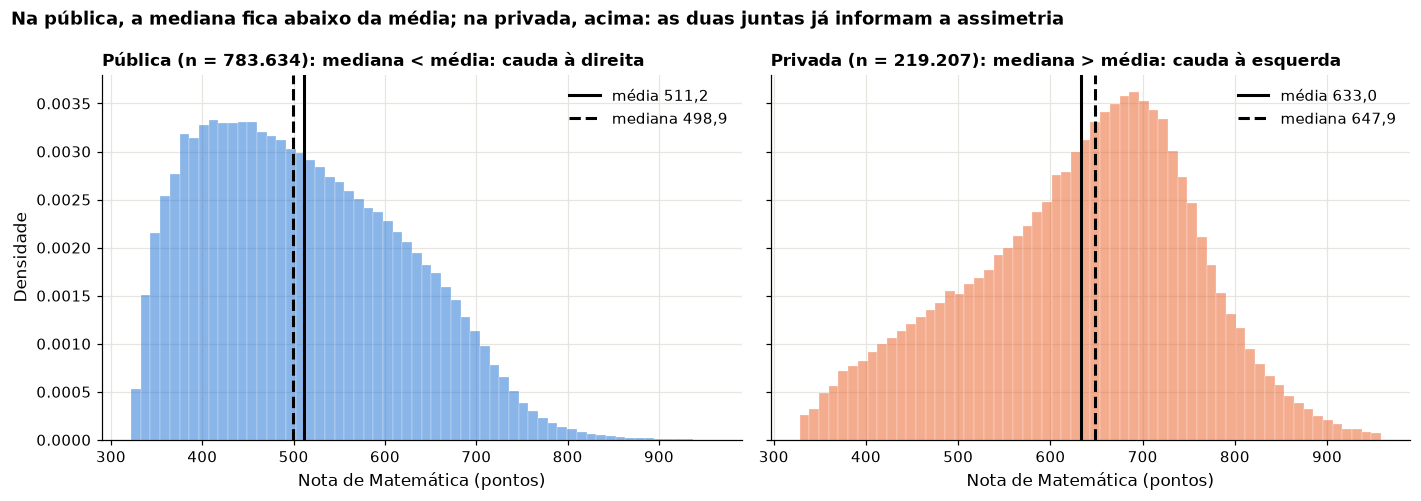

In [20]:
# (2) Histogramas de pública e privada com média (linha cheia) e mediana (tracejada)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, (cod, nome, cor) in zip(axes, ((2, 'Pública', AZUL), (3, 'Privada', LARANJA))):
    x = base.loc[base.TP_ESCOLA == cod, 'NU_NOTA_MT']
    ax.hist(x, bins=60, density=True, color=cor, alpha=0.55, edgecolor='white', linewidth=0.3)
    ax.axvline(x.mean(), color='black', lw=2, label=f'média {br(x.mean())}')
    ax.axvline(x.median(), color='black', lw=2, ls='--', label=f'mediana {br(x.median())}')
    lado = 'mediana < média: cauda à direita' if x.median() < x.mean() else 'mediana > média: cauda à esquerda'
    ax.set_title(f'{nome} (n = {br(len(x), 0)}): {lado}', fontsize=11)
    ax.set_xlabel('Nota de Matemática (pontos)')
    ax.legend(loc='upper right')
axes[0].set_ylabel('Densidade')
fig.suptitle('Na pública, a mediana fica abaixo da média; na privada, acima: as duas juntas já informam a assimetria',
             x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
salvar(fig, 'm3_media_mediana_escola')
plt.show()

**Leitura:** a privada tem média de MT bem maior, mas a forma também muda: a pública tem cauda à direita (poucos com nota alta puxam a média para cima) e a privada, cauda à esquerda. Calcular média e mediana juntas já denuncia a assimetria. A categoria "Não respondeu" (61% da base: quem já concluiu, treineiros, quem não estuda) **não** é escola nenhuma e não entra na comparação, mas fica visível na tabela.

## 3.2 Quem vai melhor depende da prova: sexo e cor/raça

Duas lições descritivas: (1) a **direção** da diferença entre sexos depende da prova; (2) as diferenças por cor/raça andam junto com a renda. Recortes nacionais: cruzar cor/raça com municípios pequenos ou escolas pode reidentificar pessoas (LGPD).

In [21]:
# Sexo: média de cada prova e diferença homens − mulheres
sexo_notas = base.groupby(base.TP_SEXO.map(ROT_SEXO))[NOTAS].mean().rename(columns=NOME_NOTA).T
sexo_notas['homens − mulheres'] = sexo_notas['Masculino'] - sexo_notas['Feminino']
display(sexo_notas.round(1))

# Cor/raça: n, média de MT e % com renda familiar até R$ 2.640 (faixas A–D)
cor_tab = (base.assign(cor=base.TP_COR_RACA.map(ROT_COR), renda_ate_2640=base.Q006.isin(list('ABCD')))
           .groupby('cor').agg(n=('NU_NOTA_MT', 'size'), média_MT=('NU_NOTA_MT', 'mean'), dp_MT=('NU_NOTA_MT', 'std'),
                               pct_renda_até_2640=('renda_ate_2640', 'mean'))
           .sort_values('média_MT', ascending=False))
cor_tab['pct_renda_até_2640'] *= 100
display(cor_tab.round(1))
print(f'η² em MT: renda (17 faixas) = {br(eta2(base.NU_NOTA_MT, base.Q006), 3)} | '
      f'cor/raça = {br(eta2(base.NU_NOTA_MT, base.TP_COR_RACA), 3)} | sexo = {br(eta2(base.NU_NOTA_MT, base.TP_SEXO), 3)}')

TP_SEXO,Feminino,Masculino,homens − mulheres
Ciências da Natureza,492.2,515.0,22.8
Ciências Humanas,525.5,536.6,11.1
Linguagens,521.5,525.9,4.5
Matemática,522.8,569.3,46.5
Redação,663.7,627.3,-36.4


,n,média_MT,dp_MT,pct_renda_até_2640
cor,,,,
Branca,1119070,577.2,127.2,44.7
Amarela,40854,544.9,138.3,61.7
Não declarado,31436,544.4,130.3,62.0
Parda,1062833,514.3,115.7,72.7
Preta,301740,499.6,107.8,76.7
Indígena,13257,470.5,101.0,83.5


η² em MT: renda (17 faixas) = 0,231 | cor/raça = 0,070 | sexo = 0,033


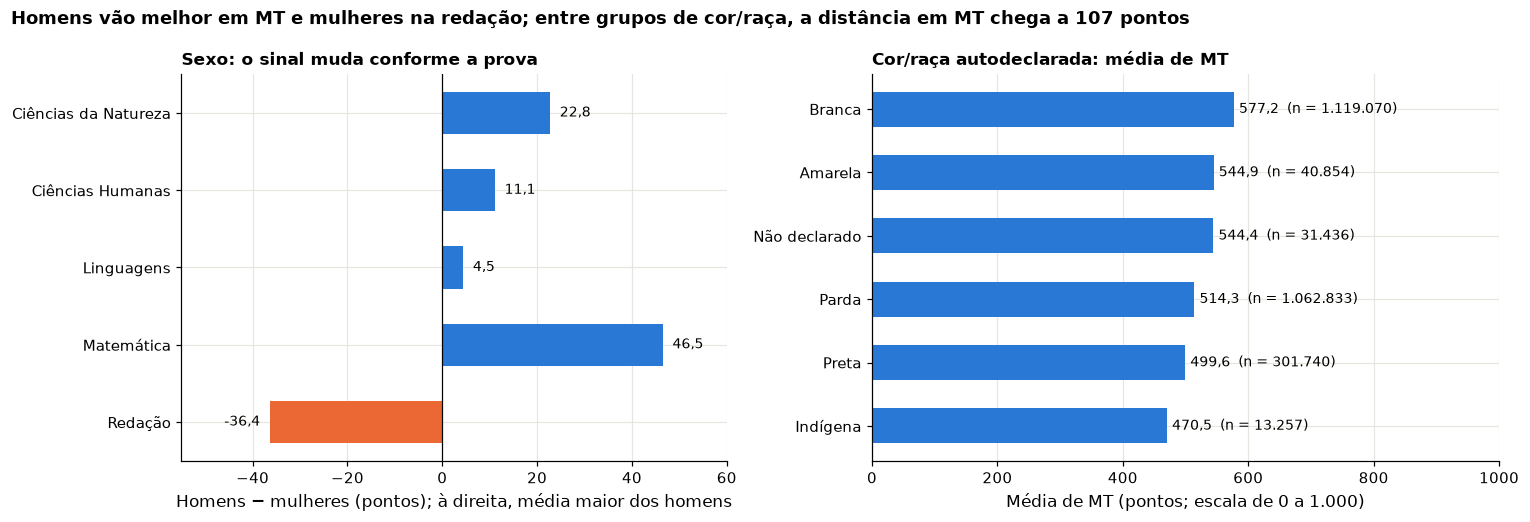

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [1, 1.15]})
ax = axes[0]
dif_s = sexo_notas['homens − mulheres']
ax.barh(range(len(dif_s)), dif_s.values, color=[AZUL if v > 0 else LARANJA for v in dif_s], height=0.55)
ax.set_yticks(range(len(dif_s)), dif_s.index)
ax.invert_yaxis()
ax.axvline(0, color='black', lw=0.8)
for i, v in enumerate(dif_s.values):
    ax.text(v + (2 if v > 0 else -2), i, br(v), va='center', ha='left' if v > 0 else 'right', fontsize=9)
ax.set_xlim(-55, 60)
ax.set_xlabel('Homens − mulheres (pontos); à direita, média maior dos homens')
ax.set_title('Sexo: o sinal muda conforme a prova', fontsize=11)
ax = axes[1]
ct = cor_tab.iloc[::-1]
ax.barh(range(len(ct)), ct['média_MT'], color=AZUL, height=0.55)
ax.set_yticks(range(len(ct)), ct.index)
for i, (v, n) in enumerate(zip(ct['média_MT'], ct['n'])):
    ax.text(v + 8, i, f'{br(v)}  (n = {br(n, 0)})', va='center', fontsize=9)
ax.set_xlim(0, 1000)
ax.set_xlabel('Média de MT (pontos; escala de 0 a 1.000)')
ax.set_title('Cor/raça autodeclarada: média de MT', fontsize=11)
fig.suptitle(f'Homens vão melhor em MT e mulheres na redação; entre grupos de cor/raça, a distância em MT chega a '
             f'{br(cor_tab.média_MT.max() - cor_tab.média_MT.min(), 0)} pontos', x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
salvar(fig, 'm3_sexo_cor_raca')
plt.show()

**Leitura:** "homens vão melhor no ENEM" é uma frase falsa sem dizer **qual prova**. Por cor/raça, a fração com renda até R$ 2.640 vai de cerca de 45% entre brancos a 77% entre pretos: a descritiva mostra a associação, mas **não separa** cor/raça de renda. Isso é o que a regressão múltipla tenta fazer (Módulo 7).

## 3.3 Gráfico honesto: o eixo truncado engana

A mesma série (média de MT por região do local de prova) em duas apresentações. À esquerda, o erro mais comum: o eixo começa perto do menor valor. À direita, a versão corrigida: eixo a partir de zero, valor e n em cada barra, título que diz a conclusão.

### IA — Prompt do gráfico honesto



```text
Papel: Você é um analista que prepara gráficos para a diretoria.

Contexto: DataFrame base com a base de análise do ENEM 2023. Colunas: NU_NOTA_MT e SG_UF_PROVA (UF do local de prova). Vou agrupar as UFs nas 5 regiões do IBGE.

Pergunta: Como mostrar a média de MT por região sem exagerar nem esconder a diferença?

Tarefa: (1) Calcule n e média de MT por região. (2) Faça dois gráficos de barras lado a lado: um com o eixo começando em 490 (o erro a evitar) e outro com o eixo de 0 a 1.000, com valor e n em cada barra. (3) Calcule a razão real entre a maior e a menor média e a razão aparente no gráfico truncado.

Restrições: Títulos que dizem a conclusão; eixos com unidade; sem 3D; matplotlib; só código.

Formato: Código comentado; depois, o checklist do gráfico honesto aplicado ao gráfico corrigido.
```

**Verificação independente** (o analista faz depois de rodar o código da IA):
- Razão real ≈ 1,16 (Sudeste ÷ Norte); a aparente no eixo truncado é muitas vezes maior
- O gráfico corrigido começa em zero e mostra n
- O mapeamento UF → região tem as 27 UFs

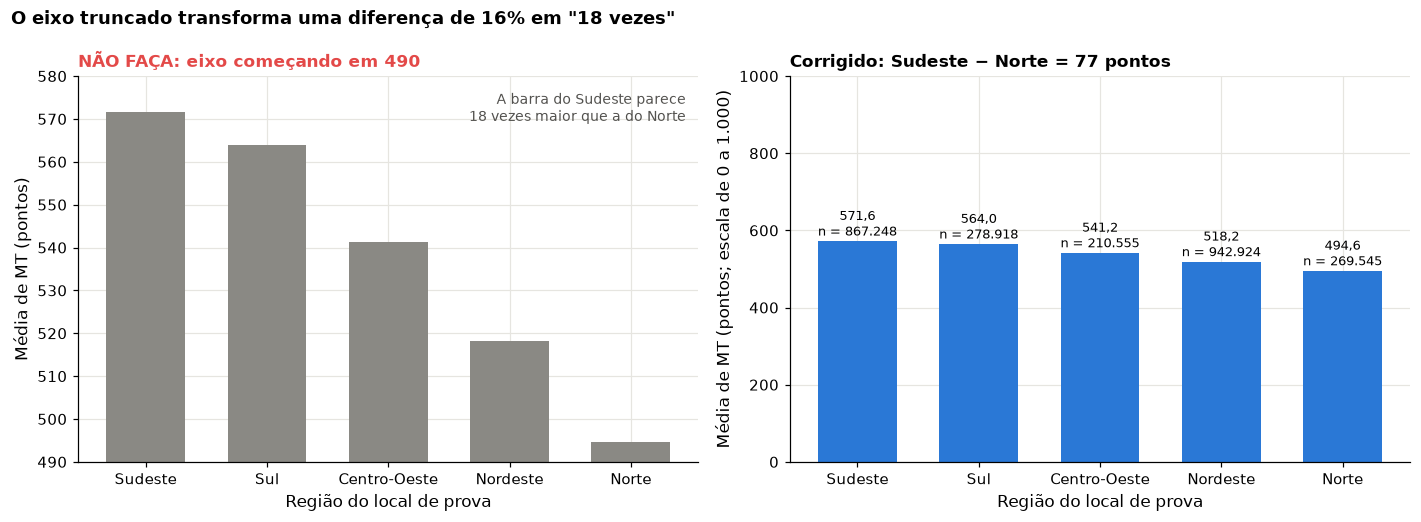

Verificação: 27 UFs mapeadas? True | razão real = 1,16 | razão visual (eixo em 490) = 17,8


In [23]:
REGIAO = {'AC': 'Norte', 'AL': 'Nordeste', 'AP': 'Norte', 'AM': 'Norte', 'BA': 'Nordeste', 'CE': 'Nordeste',
          'DF': 'Centro-Oeste', 'ES': 'Sudeste', 'GO': 'Centro-Oeste', 'MA': 'Nordeste', 'MT': 'Centro-Oeste',
          'MS': 'Centro-Oeste', 'MG': 'Sudeste', 'PA': 'Norte', 'PB': 'Nordeste', 'PR': 'Sul', 'PE': 'Nordeste',
          'PI': 'Nordeste', 'RJ': 'Sudeste', 'RN': 'Nordeste', 'RS': 'Sul', 'RO': 'Norte', 'RR': 'Norte',
          'SC': 'Sul', 'SP': 'Sudeste', 'SE': 'Nordeste', 'TO': 'Norte'}
reg = base.groupby(base.SG_UF_PROVA.map(REGIAO)).NU_NOTA_MT.agg(n='count', média='mean').sort_values('média', ascending=False)

PISO = 490                                     # início do eixo truncado (o erro a mostrar)
razao_real = reg.média.iloc[0] / reg.média.iloc[-1]
razao_visual = (reg.média.iloc[0] - PISO) / (reg.média.iloc[-1] - PISO)
dif = reg.média.iloc[0] - reg.média.iloc[-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ax = axes[0]
ax.bar(reg.index, reg.média, color=CINZA, width=0.65)
ax.set_ylim(PISO, 580)
ax.set_ylabel('Média de MT (pontos)')
ax.set_title(f'NÃO FAÇA: eixo começando em {PISO}', fontsize=11, color=VERMELHO)
ax.text(0.98, 0.96, f'A barra do {reg.index[0]} parece\n{razao_visual:.0f} vezes maior que a do {reg.index[-1]}',
        transform=ax.transAxes, ha='right', va='top', fontsize=9, color='#52514e')
ax = axes[1]
ax.bar(reg.index, reg.média, color=AZUL, width=0.65)
ax.set_ylim(0, 1000)
for i, (v, n) in enumerate(zip(reg.média, reg.n)):
    ax.text(i, v + 15, f'{br(v)}\nn = {br(n, 0)}', ha='center', fontsize=8.5)
ax.set_ylabel('Média de MT (pontos; escala de 0 a 1.000)')
ax.set_title(f'Corrigido: {reg.index[0]} − {reg.index[-1]} = {br(dif, 0)} pontos', fontsize=11)
for ax in axes:
    ax.set_xlabel('Região do local de prova')
fig.suptitle(f'O eixo truncado transforma uma diferença de {br(100 * (razao_real - 1), 0)}% em "{razao_visual:.0f} vezes"',
             x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
salvar(fig, 'm3_eixo_truncado')
plt.show()
print(f'Verificação: 27 UFs mapeadas? {len(REGIAO) == 27} | razão real = {br(razao_real, 2)} | '
      f'razão visual (eixo em {PISO}) = {br(razao_visual, 1)}')

**Checklist do gráfico honesto:** título diz a conclusão; barras começam em zero; n e fonte visíveis; eixos com unidade; sem 3D. *Fonte dos gráficos: INEP, microdados do ENEM 2023.*

---
# Módulo 4 — Probabilidade

> *"Probabilidade responde: se o mundo fosse assim, o que eu veria? Inferência responde o inverso: vi isto, como é o mundo?"*

A verificação independente em probabilidade é dupla: refazer a conta por outro caminho (a regra de Bayes, a fórmula da binomial) e **simular**.

## 4.1 Qual condicional estamos lendo?

### IA — Prompt da probabilidade condicional



```text
Papel: Você é um estatístico que explica probabilidades para gestores.

Contexto: DataFrame base com a base de análise do ENEM 2023. Colunas: NU_NOTA_MT; Q006 (renda familiar, 17 faixas A a Q; K a Q = acima de R$ 9.240); TP_COR_RACA (1 branca, 2 preta, 3 parda; autodeclarada).

Pergunta: Ter renda alta e ter nota alta (MT ≥ 700): P(nota alta | renda alta) é o mesmo que P(renda alta | nota alta)? E com cor/raça?

Tarefa: (1) Calcule a taxa de base P(renda K–Q) e P(MT ≥ 700). (2) Calcule as duas condicionais e a tabela 2 × 2 com os totais. (3) Repita com "preto ou pardo" no lugar de "renda K–Q", e P(MT ≥ 700 | branco).

Restrições: Use máscaras booleanas, sem laços. Nomeie cada probabilidade com a notação P(A | B). Não use linguagem causal. Só código.

Formato: Código comentado; depois, uma frase correta e uma frase errada (inversão da condicional) para um relatório.
```

**Verificação independente** (o analista faz depois de rodar o código da IA):
- Regra de Bayes: P(renda | nota) = P(nota | renda) × P(renda) ÷ P(nota) deve dar o mesmo que a contagem direta
- A tabela 2 × 2 soma 2.569.190
- As duas condicionais diferem quando as taxas de base diferem

In [24]:
rico = base.Q006.isin(list('KLMNOPQ'))       # renda acima de R$ 9.240
top = base.NU_NOTA_MT >= 700
print(f'P(renda K–Q) = {br(100 * rico.mean())}%   (taxa de base)')
print(f'P(MT ≥ 700) = {br(100 * top.mean())}%')
print(f'P(MT ≥ 700 | renda K–Q) = {br(100 * top[rico].mean())}%')
print(f'P(renda K–Q | MT ≥ 700) = {br(100 * rico[top].mean())}%')
pd.crosstab(rico.map({True: 'renda K–Q', False: 'demais faixas'}), top.map({True: 'MT ≥ 700', False: 'MT < 700'}),
            margins=True, margins_name='Total')

P(renda K–Q) = 9,7%   (taxa de base)
P(MT ≥ 700) = 12,0%
P(MT ≥ 700 | renda K–Q) = 41,0%
P(renda K–Q | MT ≥ 700) = 33,2%


NU_NOTA_MT,MT < 700,MT ≥ 700,Total
Q006,,,
demais faixas,2114404,205611,2320015
renda K–Q,147072,102103,249175
Total,2261476,307714,2569190


In [25]:
# A mesma lógica com cor/raça: pretos e pardos são maioria na base, mas não entre as notas altas
pp = base.TP_COR_RACA.isin([2, 3])
branca = base.TP_COR_RACA == 1
print(f'P(preto ou pardo) = {br(100 * pp.mean())}%   (taxa de base)')
print(f'P(MT ≥ 700 | preto ou pardo) = {br(100 * top[pp].mean())}% | P(MT ≥ 700 | branco) = {br(100 * top[branca].mean())}%')
print(f'P(preto ou pardo | MT ≥ 700) = {br(100 * pp[top].mean())}%')

# Verificação independente pela regra de Bayes
bayes = top[rico].mean() * rico.mean() / top.mean()
print(f'\nBayes: P(renda K–Q | MT ≥ 700) = P(MT ≥ 700 | renda) × P(renda) ÷ P(MT ≥ 700) = {br(100 * bayes)}%')

P(preto ou pardo) = 53,1%   (taxa de base)
P(MT ≥ 700 | preto ou pardo) = 6,6% | P(MT ≥ 700 | branco) = 18,4%
P(preto ou pardo | MT ≥ 700) = 29,4%

Bayes: P(renda K–Q | MT ≥ 700) = P(MT ≥ 700 | renda) × P(renda) ÷ P(MT ≥ 700) = 33,2%


**Leitura:** 41% dos de renda alta têm nota alta, mas só cerca de um terço das notas altas é de renda alta, porque renda alta é rara (taxa de base de 9,7%). Com cor/raça a taxa de base é alta: pretos e pardos são 53% da base e cerca de 29% das notas altas. "40% dos ricos tiram nota alta, logo 40% das notas altas são de ricos" é a inversão da condicional.

## 4.2 Binomial: o que esperar do chute

Numa prova de 45 itens com 5 alternativas, quem marca tudo ao acaso tem X ~ Binomial(45; 0,2) acertos. E(X) = nπ e DP = √[nπ(1−π)]. A aproximação normal da binomial é boa quando nπ ≥ 5 e n(1−π) ≥ 5.

### IA — Prompt da binomial



```text
Papel: Você é um estatístico que confere cálculos de probabilidade por simulação.

Contexto: Uma prova do ENEM tem 45 itens de 5 alternativas. Um participante marca todos ao acaso. (Exemplo conceitual: a nota do ENEM usa TRI, não o número de acertos.)

Pergunta: Quantos acertos esperar do puro chute, e qual a chance de chegar a 15 ou a 18 acertos?

Tarefa: (1) Diga qual distribuição modela X = nº de acertos e liste as suposições. (2) Com scipy.stats, calcule E(X), o DP, P(X ≥ 15) e P(X ≥ 18). (3) Simule 100.000 provas com semente 2023 e compare. (4) Para n = 5, 20 e 100 itens, desenhe a binomial exata e a normal com a mesma média e variância, e compare P(X ≤ nπ) exata e aproximada (com correção de continuidade).

Restrições: Não calcule de cabeça: só código. Diga se a simulação deve coincidir com o exato e qual a margem esperada.

Formato: Código comentado; depois, como ler P(X ≥ 18) para quem suspeita de "chute premiado".
```

**Verificação independente** (o analista faz depois de rodar o código da IA):
- E(X) = 45 × 0,2 = 9; DP = √(45 × 0,2 × 0,8) ≈ 2,68 (conta à mão)
- Exato e simulado diferem menos que ≈ 2 × √(p(1−p)/100.000)
- P(X ≥ 15) usa sf(14), não sf(15): o erro de "um a menos" é o mais comum
- A regra nπ ≥ 5 só vale a partir de n = 25 com π = 0,2

In [26]:
rng = np.random.default_rng(SEMENTE)          # gerador desta seção
N_ITENS, PI_CHUTE = 45, 0.2
X = stats.binom(N_ITENS, PI_CHUTE)
print(f'E(X) = {br(X.mean(), 0)} acertos | DP = {br(X.std(), 2)} | conta à mão: √(45·0,2·0,8) = {br(np.sqrt(45 * 0.2 * 0.8), 2)}')
sim = rng.binomial(N_ITENS, PI_CHUTE, size=100_000)
for k in (15, 18):
    p_exato = X.sf(k - 1)                     # P(X ≥ k) = 1 − P(X ≤ k − 1)
    margem = 2 * np.sqrt(p_exato * (1 - p_exato) / 100_000)
    print(f'P(X ≥ {k}) = {br(100 * p_exato, 2)}% | simulado = {br(100 * (sim >= k).mean(), 2)}% | margem esperada ±{br(100 * margem, 2)} p.p.')

E(X) = 9 acertos | DP = 2,68 | conta à mão: √(45·0,2·0,8) = 2,68
P(X ≥ 15) = 2,50% | simulado = 2,54% | margem esperada ±0,10 p.p.
P(X ≥ 18) = 0,17% | simulado = 0,17% | margem esperada ±0,03 p.p.


n =   5: P(X ≤ 1) exata = 0,7373 | normal com correção de continuidade = 0,7119 | diferença = 0,0254
n =  20: P(X ≤ 4) exata = 0,6296 | normal com correção de continuidade = 0,6101 | diferença = 0,0196
n = 100: P(X ≤ 20) exata = 0,5595 | normal com correção de continuidade = 0,5497 | diferença = 0,0097


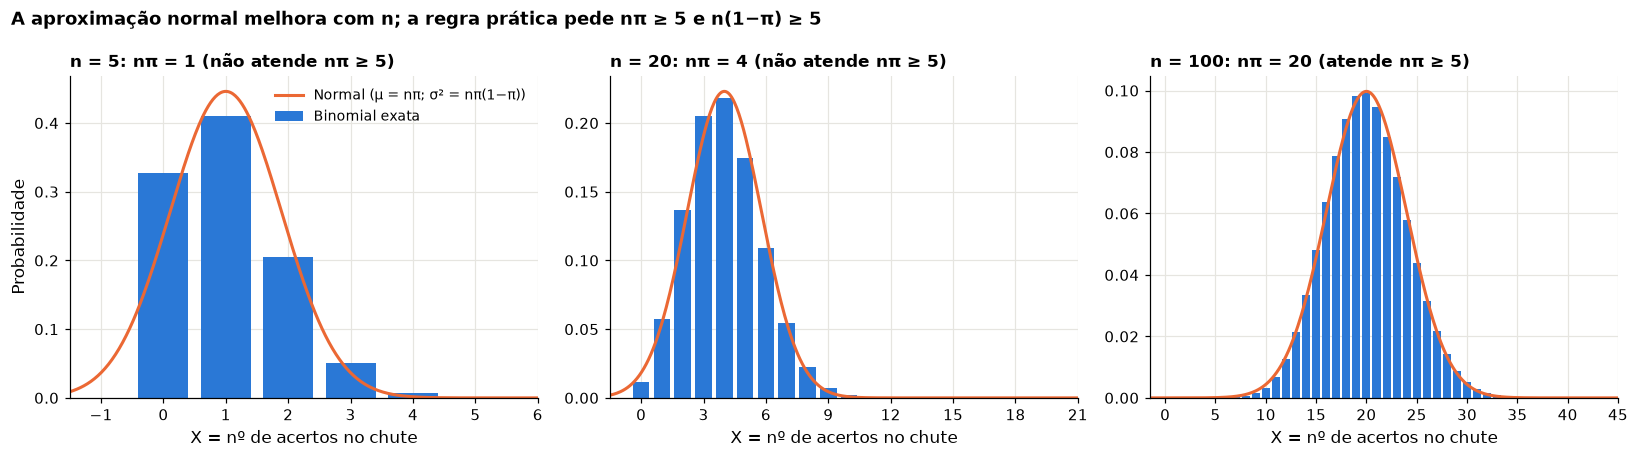

In [27]:
# Aproximação normal da binomial: melhora com n
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, n in zip(axes, (5, 20, 100)):
    k = np.arange(n + 1)
    mu, dp = n * PI_CHUTE, np.sqrt(n * PI_CHUTE * (1 - PI_CHUTE))
    ax.bar(k, stats.binom.pmf(k, n, PI_CHUTE), color=AZUL, width=0.8, label='Binomial exata')
    x_max = n + 1 if n < 100 else 45
    xs = np.linspace(-1.5, x_max, 400)
    ax.plot(xs, stats.norm.pdf(xs, mu, dp), color=LARANJA, lw=2, label='Normal (μ = nπ; σ² = nπ(1−π))')
    ax.set_xlim(-1.5, x_max)
    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True))
    atende = 'atende' if min(n * PI_CHUTE, n * (1 - PI_CHUTE)) >= 5 else 'não atende'
    ax.set_title(f'n = {n}: nπ = {br(n * PI_CHUTE, 0)} ({atende} nπ ≥ 5)', fontsize=11)
    ax.set_xlabel('X = nº de acertos no chute')
    c = int(mu)
    exato, aprox = stats.binom.cdf(c, n, PI_CHUTE), stats.norm.cdf(c + 0.5, mu, dp)
    print(f'n = {n:3d}: P(X ≤ {c}) exata = {br(exato, 4)} | normal com correção de continuidade = {br(aprox, 4)} | diferença = {br(abs(exato - aprox), 4)}')
axes[0].set_ylabel('Probabilidade')
axes[0].legend(loc='upper right', fontsize=9)
fig.suptitle('A aproximação normal melhora com n; a regra prática pede nπ ≥ 5 e n(1−π) ≥ 5', x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
salvar(fig, 'm4_binomial_normal')
plt.show()

## 4.3 A distribuição normal e o Teorema Central do Limite

Duas perguntas diferentes: (1) a normal **descreve** as notas? (regra 68-95-99,7); (2) por que a normal aparece mesmo quando a variável **não** é normal? (TCL: a **média de amostras** tende à normal).

### IA — Prompt da normal e do TCL



```text
Papel: Você é um estatístico que testa modelos contra os dados.

Contexto: DataFrame base (base de análise do ENEM 2023) com as cinco notas NU_NOTA_CN, NU_NOTA_CH, NU_NOTA_LC, NU_NOTA_MT e NU_NOTA_REDACAO; DataFrame insc com todos os inscritos e TP_PRESENCA_MT (1 = presente).

Pergunta: A regra 68-95-99,7 da normal vale para as notas? E a média de amostras de uma variável 0/1 fica normal quando n cresce?

Tarefa: (1) Para cada nota, calcule média, DP, assimetria e o % de participantes a menos de 1, 2 e 3 DP da média. (2) Desenhe o histograma de MT com a normal de mesma média e DP. (3) Com a presença em MT (0/1), sorteie 5.000 amostras de n = 5, 30 e 400 (semente 2023), desenhe o histograma das proporções e compare o DP delas com √(p(1−p)/n).

Restrições: Use o DP populacional (ddof = 0) na regra 68-95-99,7, porque a base é tratada como população. Só código.

Formato: Código comentado; depois, em 3 frases, onde a normal é um bom modelo e onde não é.
```

**Verificação independente** (o analista faz depois de rodar o código da IA):
- Na normal: 68,3% | 95,4% | 99,7% (stats.norm.cdf(1) − stats.norm.cdf(−1) etc.)
- MT é mais achatada: bem menos de 68% a 1 DP
- DP das proporções simuladas ≈ √(p(1−p)/n) em cada n

In [28]:
# (1) Regra 68-95-99,7: % de participantes a menos de 1, 2 e 3 desvios padrão da média
linhas = {}
for nota in NOTAS:
    x = base[nota].to_numpy()
    z = (x - x.mean()) / x.std()             # ddof = 0: a base é a população
    linhas[NOME_NOTA[nota]] = {'média': x.mean(), 'dp': x.std(), 'assimetria': stats.skew(x),
                               '|z|<1 (%)': 100 * (abs(z) < 1).mean(), '|z|<2 (%)': 100 * (abs(z) < 2).mean(),
                               '|z|<3 (%)': 100 * (abs(z) < 3).mean()}
print('Esperado na normal:', ' | '.join(f'{br(100 * (stats.norm.cdf(k) - stats.norm.cdf(-k)))}%' for k in (1, 2, 3)))
pd.DataFrame(linhas).T.round(2)

Esperado na normal: 68,3% | 95,4% | 99,7%


,média,dp,assimetria,|z|<1 (%),|z|<2 (%),|z|<3 (%)
Ciências da Natureza,500.93,78.77,0.35,68.21,95.39,99.57
Ciências Humanas,529.74,83.93,-0.26,67.82,95.18,99.97
Linguagens,523.17,72.26,-0.31,68.80,95.19,99.74
Matemática,540.60,124.91,0.37,62.51,97.39,99.88
Redação,649.81,174.88,-0.05,64.72,97.88,99.98


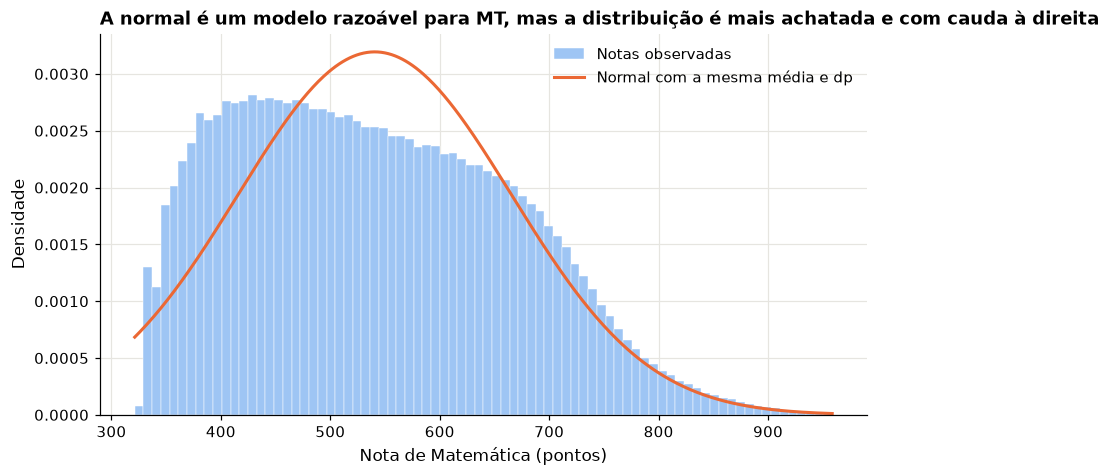

P(MT > 600): normal = 31,7% | observado = 32,7%
P(MT > 700): normal = 10,1% | observado = 12,0%
P(MT > 800): normal = 1,9% | observado = 2,2%


In [29]:
# (2) MT contra a normal de mesma média e DP
mt = base.NU_NOTA_MT.to_numpy()
MU, SIGMA = mt.mean(), mt.std()   # parâmetros da "população" do curso
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(mt, bins=80, density=True, color='#9ec5f4', edgecolor='white', linewidth=0.3, label='Notas observadas')
xs = np.linspace(mt.min(), mt.max(), 400)
ax.plot(xs, stats.norm.pdf(xs, MU, SIGMA), color=LARANJA, lw=2, label='Normal com a mesma média e dp')
ax.set_xlabel('Nota de Matemática (pontos)')
ax.set_ylabel('Densidade')
ax.set_title('A normal é um modelo razoável para MT, mas a distribuição é mais achatada e com cauda à direita')
ax.legend()
salvar(fig, 'm4_normal_mt')
plt.show()
for lim in (600, 700, 800):
    print(f'P(MT > {lim}): normal = {br(100 * stats.norm.sf(lim, MU, SIGMA))}% | observado = {br(100 * (mt > lim).mean())}%')

n =   5: dp das proporções = 0,2074 | teórico √(p(1−p)/n) = 0,2078
n =  30: dp das proporções = 0,0825 | teórico √(p(1−p)/n) = 0,0849
n = 400: dp das proporções = 0,0232 | teórico √(p(1−p)/n) = 0,0232


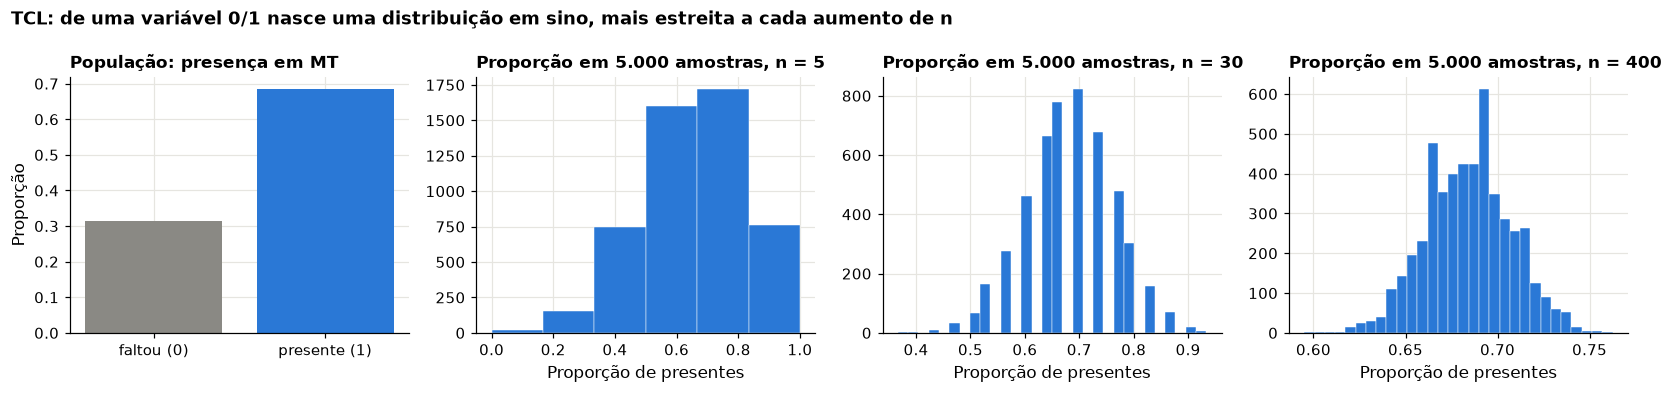

In [30]:
# (3) TCL com uma variável nada normal: a presença em MT (0 ou 1), todos os inscritos
rng = np.random.default_rng(SEMENTE)          # gerador desta seção
presenca = (insc.TP_PRESENCA_MT == 1).astype(int).to_numpy()
p_pop = presenca.mean()
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
axes[0].bar(['faltou (0)', 'presente (1)'], [1 - p_pop, p_pop], color=[CINZA, AZUL])
axes[0].set_title('População: presença em MT', fontsize=11)
axes[0].set_ylabel('Proporção')
for ax, n in zip(axes[1:], (5, 30, 400)):
    medias = rng.choice(presenca, size=(5000, n)).mean(axis=1)
    ax.hist(medias, bins=30 if n > 5 else 6, color=AZUL, edgecolor='white', linewidth=0.3)
    ax.set_title(f'Proporção em 5.000 amostras, n = {n}', fontsize=11)
    ax.set_xlabel('Proporção de presentes')
    print(f'n = {n:3d}: dp das proporções = {br(medias.std(ddof=1), 4)} | teórico √(p(1−p)/n) = {br(np.sqrt(p_pop * (1 - p_pop) / n), 4)}')
fig.suptitle('TCL: de uma variável 0/1 nasce uma distribuição em sino, mais estreita a cada aumento de n', x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
salvar(fig, 'm4_tcl_presenca')
plt.show()

**Leitura:** a regra 68-95-99,7 é uma boa aproximação para CN, CH e LC; Matemática é mais achatada (bem menos que 68% a 1 DP). A normal é um **modelo**, não um fato. Já a **média de amostras** fica normal mesmo partindo de uma variável 0/1: é o TCL, e é por isso que intervalos de confiança e testes funcionam (Módulos 5 e 6). O desvio padrão dessa distribuição das médias tem nome, **erro padrão**, e abre o Módulo 5.

---
# Módulo 5 — Amostragem

**Por que amostrar, se temos todos?** No trabalho real (pesquisa de clima, auditoria de prontuários de ocorrências, satisfação) quase sempre temos **só uma amostra**. Aqui tratamos a base de análise como **população**, conhecemos o valor verdadeiro e **sorteamos amostras** para ver como as estimativas se comportam. É um laboratório.

> *"Com sorteio, o erro se mede; sem sorteio, o erro é desconhecido e quase sempre tem direção."*

## 5.1 Erro padrão, o laboratório e o intervalo de confiança

### IA — Prompt do erro padrão e do IC



```text
Papel: Você é um estatístico que mostra o erro amostral por simulação.

Contexto: DataFrame base com a base de análise do ENEM 2023 (2.569.190 participantes), que vou tratar como população. Coluna: NU_NOTA_MT.

Pergunta: Quão perto uma amostra aleatória chega da média verdadeira de MT, e como ler o intervalo de confiança?

Tarefa: (1) Calcule μ e σ da população e o erro padrão teórico σ/√n para n = 100, 400 e 1.600. (2) Sorteie, com semente 2023, uma amostra aleatória simples de n = 400 e calcule a média e o IC95% pela t. (3) Sorteie 1.000 amostras de n = 400 e compare o DP das 1.000 médias com σ/√n. (4) Sorteie 100 amostras de n = 50, calcule o IC95% de cada uma e conte quantos contêm μ; desenhe os 100 intervalos.

Restrições: Use o DP amostral (ddof = 1) no IC. Não use a frase "95% de probabilidade de μ estar no intervalo". Só código.

Formato: Código comentado; depois, a leitura correta e a leitura errada de um IC de 95%.
```

**Verificação independente** (o analista faz depois de rodar o código da IA):
- σ/√n com σ = 124,91: 12,5 (n = 100), 6,25 (n = 400), 3,1 (n = 1.600)
- O DP das 1.000 médias fica perto de 6,25
- Cerca de 95 dos 100 intervalos contêm μ (o número exato varia com a semente)
- Quadruplicar n divide o erro padrão por 2

In [31]:
# (1) A lei da raiz de n: EP = σ / √n
print(f'População (base): N = {br(len(mt), 0)} | μ = {br(MU, 2)} | σ = {br(SIGMA, 2)}')
pd.DataFrame({'n': [100, 400, 1600], 'EP = σ/√n (pontos)': [SIGMA / np.sqrt(n) for n in (100, 400, 1600)]}).set_index('n').round(2)

População (base): N = 2.569.190 | μ = 540,60 | σ = 124,91


,EP = σ/√n (pontos)
n,
100,12.49
400,6.25
1600,3.12


Amostra n = 400: média = 539,7 | S = 124,1 | IC95% = [527,5; 551,9]
Erro amostral desta amostra = -0,9 pontos | o IC contém μ = 540,60? True


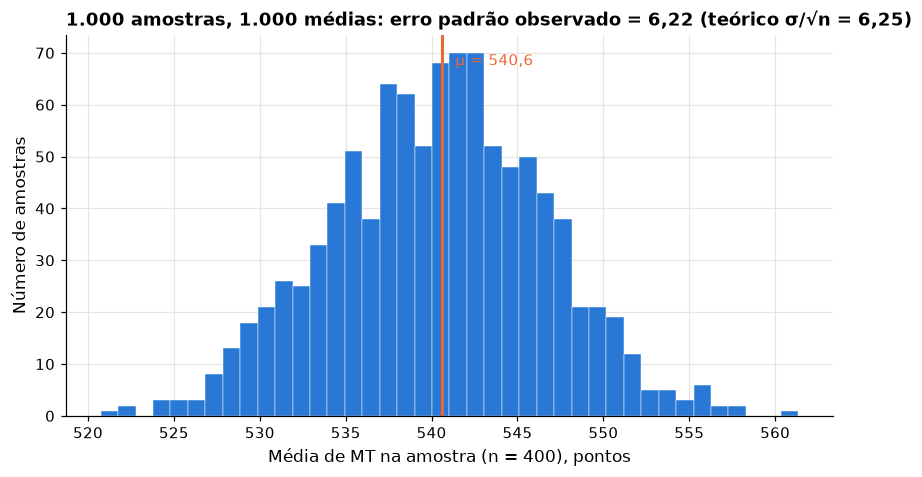

Erro padrão observado = 6,22 | teórico σ/√n = 6,25 | médias entre 520,7 e 561,3


In [32]:
# (2) Uma amostra aleatória simples de n = 400: o que o analista teria na vida real
rng = np.random.default_rng(SEMENTE)          # gerador desta seção
amostra = rng.choice(mt, size=400, replace=False)
m, lo, hi = ic_media(amostra)
print(f'Amostra n = 400: média = {br(m)} | S = {br(amostra.std(ddof=1))} | IC95% = [{br(lo)}; {br(hi)}]')
print(f'Erro amostral desta amostra = {br(m - MU)} pontos | o IC contém μ = {br(MU, 2)}? {lo <= MU <= hi}')

# (3) 1.000 amostras de n = 400, 1.000 médias
medias_400 = rng.choice(mt, size=(1000, 400)).mean(axis=1)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(medias_400, bins=40, color=AZUL, edgecolor='white', linewidth=0.3)
ax.axvline(MU, color=LARANJA, lw=2)
ax.text(MU + 0.5, ax.get_ylim()[1] * 0.92, f' μ = {br(MU)}', color=LARANJA)
ax.set_xlabel('Média de MT na amostra (n = 400), pontos')
ax.set_ylabel('Número de amostras')
ax.set_title(f'1.000 amostras, 1.000 médias: erro padrão observado = {br(medias_400.std(ddof=1), 2)} (teórico σ/√n = {br(SIGMA / 20, 2)})')
salvar(fig, 'm5_distribuicao_medias')
plt.show()
print(f'Erro padrão observado = {br(medias_400.std(ddof=1), 2)} | teórico σ/√n = {br(SIGMA / 20, 2)} | '
      f'médias entre {br(medias_400.min())} e {br(medias_400.max())}')

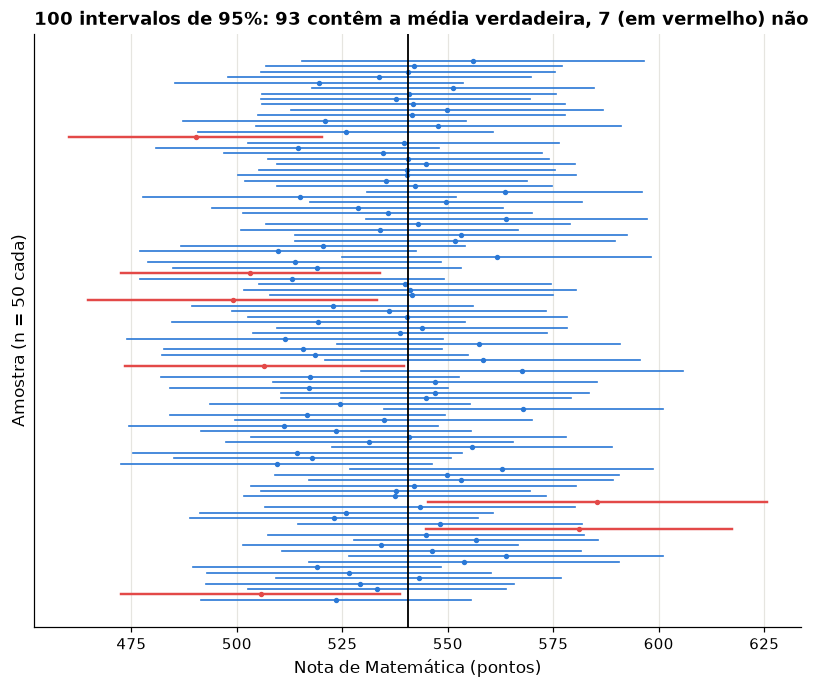

93 de 100 intervalos contêm μ = 540,60


In [33]:
# (4) Como ler um IC: 100 amostras de n = 50, 100 intervalos
rng = np.random.default_rng(SEMENTE)          # gerador desta seção
n = 50
amostras = rng.choice(mt, size=(100, n))
medias = amostras.mean(axis=1)
ep = amostras.std(axis=1, ddof=1) / np.sqrt(n)
t = stats.t.ppf(0.975, n - 1)
lo, hi = medias - t * ep, medias + t * ep
acertou = (lo <= MU) & (MU <= hi)

fig, ax = plt.subplots(figsize=(9, 7))
for i in range(100):
    cor = AZUL if acertou[i] else VERMELHO
    ax.plot([lo[i], hi[i]], [i, i], color=cor, lw=1.6 if not acertou[i] else 1.1)
    ax.plot(medias[i], i, 'o', color=cor, ms=2.5)
ax.axvline(MU, color='black', lw=1.2)
ax.set_xlabel('Nota de Matemática (pontos)')
ax.set_ylabel('Amostra (n = 50 cada)')
ax.set_yticks([])
ax.set_title(f'100 intervalos de 95%: {acertou.sum()} contêm a média verdadeira, {100 - acertou.sum()} (em vermelho) não')
salvar(fig, 'm5_cem_intervalos')
plt.show()
print(f'{acertou.sum()} de 100 intervalos contêm μ = {br(MU, 2)}')

**Como ler:** o parâmetro μ é fixo; **o intervalo é que varia**. *Certo:* "95% dos intervalos construídos assim contêm o parâmetro." *Errado:* "há 95% de probabilidade de μ estar neste intervalo" (este intervalo contém μ ou não; não sabemos qual).

## 5.2 Tamanho da amostra: quanto custa a precisão

Fórmulas (BAR 9.5): média, n = (z·σ/E)²; proporção, n = z²·π(1−π)/E². O erro tolerável **E** e a confiança são **decisões do gestor**, não do estatístico.

### IA — Prompt do tamanho da amostra



```text
Papel: Você é um estatístico que planeja amostras para estimar médias e proporções.

Contexto: Quero estimar a média de MT do ENEM 2023 com 95% de confiança. Tenho uma amostra piloto de 400 participantes (array amostra, nota de MT) e a base inteira (array mt) para conferir por simulação.

Pergunta: Quantos participantes preciso para errar no máximo ±10 pontos? E ±5? E para uma proporção com ±3 pontos percentuais?

Tarefa: (1) Escreva funções n_media(sigma, E) e n_proporcao(E, p = 0,5, N opcional para população finita). (2) Use o DP da amostra piloto como σ. (3) Calcule n para ±10 e ±5 pontos e para a proporção com ±3 p.p. (pior caso π = 0,5). (4) Confira por simulação: com o n de ±5 pontos, sorteie 2.000 amostras e conte quantas erram até 5 pontos.

Restrições: Arredonde n sempre para cima. Mostre a fórmula em comentário. Só código.

Formato: Código comentado; depois, uma frase para o gestor sobre o custo de reduzir o erro pela metade.
```

**Verificação independente** (o analista faz depois de rodar o código da IA):
- Metade do erro, quatro vezes a amostra (n de ±5 ≈ 4 × n de ±10)
- Proporção, ±3 p.p., π = 0,5: n = 1.068
- Na simulação, cerca de 95% das amostras erram até 5 pontos

In [34]:
def n_media(sigma, E, conf=0.95):
    # n = (z · σ / E)²
    z = stats.norm.ppf((1 + conf) / 2)
    return int(np.ceil((z * sigma / E) ** 2))

def n_proporcao(E, p=0.5, conf=0.95, N=None):
    # n = z² · π(1 − π) / E², com correção para população finita se N for dado
    z = stats.norm.ppf((1 + conf) / 2)
    n0 = z ** 2 * p * (1 - p) / E ** 2
    if N is not None:
        n0 = n0 / (1 + (n0 - 1) / N)
    return int(np.ceil(n0))

S_piloto = amostra.std(ddof=1)              # σ desconhecido: usar a amostra piloto da seção 5.1
print(f'σ estimado pela piloto (n = 400): {br(S_piloto, 2)}')
for E in (10, 5):
    print(f'Média de MT com erro ±{E} pontos (95%): n = {br(n_media(S_piloto, E), 0)}')
print('Proporção com erro ±3 p.p., pior caso π = 0,5: n =', br(n_proporcao(0.03), 0))

# Verificação por simulação
rng = np.random.default_rng(SEMENTE)          # gerador desta seção
n5 = n_media(S_piloto, 5)
erros = np.abs(rng.choice(mt, size=(2000, n5)).mean(axis=1) - MU)
print(f'Com n = {br(n5, 0)}: {br(100 * (erros <= 5).mean())}% das 2.000 amostras erraram ≤ 5 pontos (esperado ≈ 95%)')

σ estimado pela piloto (n = 400): 124,06
Média de MT com erro ±10 pontos (95%): n = 592
Média de MT com erro ±5 pontos (95%): n = 2.366
Proporção com erro ±3 p.p., pior caso π = 0,5: n = 1.068
Com n = 2.366: 95,2% das 2.000 amostras erraram ≤ 5 pontos (esperado ≈ 95%)


## 5.3 Quando a amostra engana: conveniência, seleção e Simpson

### IA — Prompt dos vieses



```text
Papel: Você é um revisor de metodologia que procura vieses antes de qualquer conclusão.

Contexto: DataFrame base (base de análise do ENEM 2023, notas e SG_UF_PROVA, IN_TREINEIRO, TP_FAIXA_ETARIA) e DataFrame insc (todos os inscritos, com TP_PRESENCA_MT, Q006, TP_COR_RACA, TP_SEXO).

Pergunta: Quando uma amostra grande ainda engana? Três casos: só ouvir o DF; analisar só quem compareceu; comparar treineiros e demais sem olhar a idade.

Tarefa: (1) Conveniência: sorteie amostras de n = 25 a 3.200 só entre os participantes do DF e do Brasil todo, 500 por n (semente 2023), e mostre a média das estimativas e a faixa de 95% por n. (2) Seleção: % de presentes em MT por faixa de renda (Q006), por cor/raça e por sexo, entre todos os inscritos. (3) Simpson: média de MT de treineiros e demais no total e em 5 faixas etárias, com o n de cada casela.

Restrições: Não conclua causa. Mostre sempre o n. Só código.

Formato: Código comentado; depois, uma frase por caso dizendo o que um relatório ingênuo concluiria e por que estaria errado.
```

**Verificação independente** (o analista faz depois de rodar o código da IA):
- Viés do DF = média do DF − média do Brasil, e ele não diminui com n
- Presença: menor na faixa A (sem renda) que nas altas; quase igual entre os sexos
- Simpson: treineiros acima no total e abaixo em cada faixa; a tabela de n explica por quê

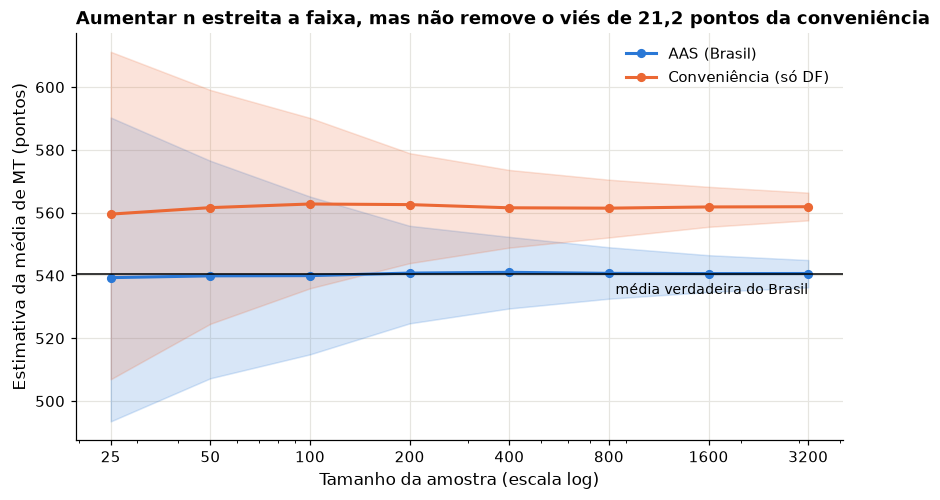

Média do DF = 561,8 (N = 48.592) | Brasil = 540,6 | viés = 21,2 pontos


In [35]:
# (1) Tamanho não cura viés: amostra de conveniência (só o DF)
rng = np.random.default_rng(SEMENTE)          # gerador desta seção
mt_df = base.loc[base.SG_UF_PROVA == 'DF', 'NU_NOTA_MT'].to_numpy()
ns = np.array([25, 50, 100, 200, 400, 800, 1600, 3200])
res = {'AAS (Brasil)': [], 'Conveniência (só DF)': []}
for n in ns:
    res['AAS (Brasil)'].append(rng.choice(mt, size=(500, n)).mean(axis=1))
    res['Conveniência (só DF)'].append(rng.choice(mt_df, size=(500, n)).mean(axis=1))

fig, ax = plt.subplots(figsize=(9, 4.8))
for (nome, ests), cor in zip(res.items(), (AZUL, LARANJA)):
    ests = np.array(ests)
    ax.fill_between(ns, np.percentile(ests, 2.5, axis=1), np.percentile(ests, 97.5, axis=1), color=cor, alpha=0.18)
    ax.plot(ns, ests.mean(axis=1), 'o-', color=cor, lw=2, ms=5, label=nome)
ax.axhline(MU, color='black', lw=1)
ax.text(ns[-1], MU - 3, 'média verdadeira do Brasil', ha='right', va='top', fontsize=9)
ax.set_xscale('log')
ax.set_xticks(ns, [str(v) for v in ns])
ax.set_xlabel('Tamanho da amostra (escala log)')
ax.set_ylabel('Estimativa da média de MT (pontos)')
ax.set_title(f'Aumentar n estreita a faixa, mas não remove o viés de {br(mt_df.mean() - MU)} pontos da conveniência')
ax.legend(loc='upper right')
salvar(fig, 'm5_conveniencia_vies')
plt.show()
print(f'Média do DF = {br(mt_df.mean())} (N = {br(len(mt_df), 0)}) | Brasil = {br(MU)} | viés = {br(mt_df.mean() - MU)} pontos')

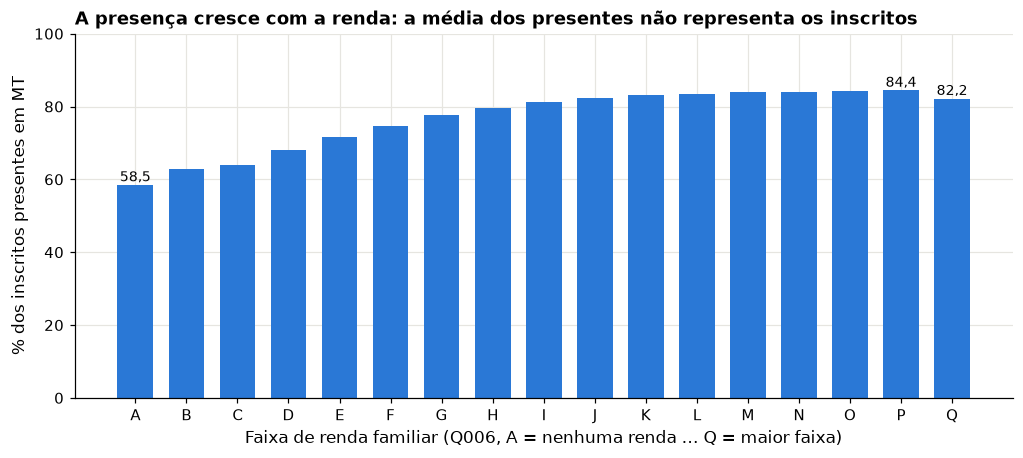

,inscritos,% presentes em MT
TP_COR_RACA,,
Branca,1575848,73.6
Amarela,64512,66.6
Parda,1706798,65.8
Não declarado,52575,63.7
Preta,509511,62.5
Indígena,24711,58.8


% presentes em MT por sexo: {'Feminino': '68,5', 'Masculino': '68,4'}


In [36]:
# (2) Viés de seleção: quem comparece à prova (todos os inscritos)
pres_renda = insc.groupby('Q006').TP_PRESENCA_MT.apply(lambda s: 100 * (s == 1).mean()).loc[FAIXAS_RENDA]
fig, ax = plt.subplots(figsize=(11, 4.3))
ax.bar(pres_renda.index, pres_renda.values, color=AZUL, width=0.7)
for i, v in enumerate(pres_renda.values):
    if i in (0, len(pres_renda) - 1) or i == int(np.argmax(pres_renda.values)):
        ax.text(i, v + 1, br(v), ha='center', fontsize=9)
ax.set_ylim(0, 100)
ax.set_xlabel('Faixa de renda familiar (Q006, A = nenhuma renda … Q = maior faixa)')
ax.set_ylabel('% dos inscritos presentes em MT')
ax.set_title('A presença cresce com a renda: a média dos presentes não representa os inscritos')
salvar(fig, 'm5_presenca_por_renda')
plt.show()

cor_insc = insc.TP_COR_RACA.map(ROT_COR)
pres_cor = pd.DataFrame({'inscritos': cor_insc.value_counts(),
                         '% presentes em MT': insc.groupby(cor_insc).TP_PRESENCA_MT.apply(lambda s: 100 * (s == 1).mean())})
display(pres_cor.sort_values('% presentes em MT', ascending=False).round(1))
pres_sexo = insc.groupby(insc.TP_SEXO.map(ROT_SEXO)).TP_PRESENCA_MT.apply(lambda s: 100 * (s == 1).mean())
print('% presentes em MT por sexo:', {k: br(v) for k, v in pres_sexo.items()})

In [37]:
# (3) Paradoxo de Simpson: treineiros × demais, por faixa etária
def faixa_etaria(c):
    return ('1) até 17 anos' if c <= 2 else '2) 18 anos' if c == 3 else '3) 19–20 anos' if c <= 5
            else '4) 21–25 anos' if c <= 10 else '5) 26 anos ou mais')
faixa = base.TP_FAIXA_ETARIA.map(faixa_etaria).rename('faixa etária')
treino = base.IN_TREINEIRO.map({0: 'Demais', 1: 'Treineiros'}).rename('grupo')

simpson = base.groupby([faixa, treino]).NU_NOTA_MT.mean().unstack()
simpson.loc['TOTAL'] = base.groupby(treino).NU_NOTA_MT.mean()
contagem = pd.crosstab(faixa, treino, margins=True, margins_name='TOTAL')
display(simpson.round(1).join(contagem.rename(columns=lambda c: f'n {c}')).drop(columns='n TOTAL'))
print(f"{br(100 * contagem.loc['1) até 17 anos', 'Treineiros'] / contagem.loc['TOTAL', 'Treineiros'])}% dos treineiros "
      f"têm até 17 anos (a faixa de maior média); entre os demais, {br(100 * contagem.loc['1) até 17 anos', 'Demais'] / contagem.loc['TOTAL', 'Demais'])}%.")

grupo,Demais,Treineiros,n Demais,n Treineiros
faixa etária,,,,
1) até 17 anos,556.3,552.4,407788,463293
2) 18 anos,540.7,493.6,637994,16896
3) 19–20 anos,540.0,471.1,439740,3641
4) 21–25 anos,537.8,432.7,318140,520
5) 26 anos ou mais,506.3,422.4,280527,651
TOTAL,538.5,549.4,2084189,485001


95,5% dos treineiros têm até 17 anos (a faixa de maior média); entre os demais, 19,6%.


**Leitura:** (1) a amostra só do DF mira no alvo errado, e aumentar n só a deixa mais confiante no erro. (2) A base de notas só tem quem compareceu, e a presença cresce com a renda e varia por cor/raça: as notas sub-representam os grupos que mais faltam. (3) No total, os treineiros têm média **maior**; em **cada** faixa etária, **menor**. A composição etária inverte o sinal: quase todos os treineiros têm até 17 anos. É descrição de dados observacionais, não efeito de "ser treineiro".

---
# Módulo 6 — Testes de hipóteses: três testes completos

> *"Um teste de hipóteses responde a uma única pergunta: se não houvesse efeito nenhum, quão estranho seria o que eu observei? Não responde se o efeito é grande, importante ou causal."*

Cada teste segue o mesmo roteiro, do planejamento ao relato:

1. **Pergunta e hipóteses** (H₀, H₁, bilateral, α = 0,05)
2. **Margem de relevância**, definida antes de olhar os dados
3. **Tamanho da amostra pelo poder** (`statsmodels`)
4. **Sorteio da amostra** (gerador próprio, semente 2023)
5. **Pressupostos**
6. **O teste**
7. **Efeito, IC e tamanho do efeito**
8. **Relato** (e verificação independente)

## 6.0 Pré-registro (escrito antes de rodar)

| | Ex. 1 | Ex. 2 | Ex. 3 |
|---|---|---|---|
| Pergunta | MT difere entre escolas **públicas** e **privadas**? | MT difere entre **federal, estadual, municipal e privada**? | Escolaridade do pai e renda familiar estão associadas? |
| Teste | t de Welch | ANOVA + Tukey | qui-quadrado de independência |
| Menor efeito relevante | d = 0,2 | d = 0,2 entre dois grupos | V de Cramér = 0,1 |
| n | por grupo (`TTestIndPower`) | por grupo, α ÷ 6 pares (Bonferroni) | total (`GofChisquarePower`) e esperadas ≥ 5 |
| Relato | efeito + IC95% + valor-p + tamanho do efeito + limitações, **inclusive se não for significativo** | | |

## 6.1 Ex. 1 — Matemática: escolas públicas × privadas (t de Welch)

### IA — Prompt do Ex. 1: o teste t



```text
Papel: Você é um estatístico revisando uma análise para gestores públicos.

Contexto: DataFrame base com a base de análise do ENEM 2023, tratada como população. Colunas: NU_NOTA_MT e TP_ESCOLA (2 pública, 3 privada; 1 = não respondeu, fora da análise). Dados observacionais, sem sorteio de quem estuda onde.

Pergunta: A nota média de MT difere entre públicas e privadas? H0: médias iguais; bilateral; α = 0,05; menor efeito relevante: d = 0,2.

Tarefa: (1) Converta d = 0,2 em pontos de MT e calcule o n por grupo para poder de 80% (TTestIndPower). (2) Sorteie n em cada grupo, sem reposição (semente 2023), e cheque os pressupostos. (3) t de Welch (ttest_ind com equal_var=False): diferença, IC95% e d de Cohen; classifique o IC contra a margem. (4) Controle negativo: embaralhe o grupo 1.000 vezes e conte quantos p < 0,05.

Restrições: Só código, sem resultados. Não use "poder observado". Não escreva "prova", "causa" nem "efeito da escola".

Formato: Suposições e como checá-las; código comentado; como ler cada saída, inclusive se p > 0,05.
```

**Verificação independente** (o analista faz depois de rodar o código da IA):
- n por grupo = 394 (o mesmo para qualquer par com d = 0,2, poder 80%, α = 0,05)
- Sorteados só com TP_ESCOLA 2 ou 3, sem repetição
- Conferir t à mão: diferença ÷ √(s₁²/n₁ + s₂²/n₂)
- Controle negativo: cerca de 5% de p < 0,05
- Comparar o IC da amostra com a diferença verdadeira da população

**Passo 1 — Pergunta e hipóteses.** H₀: μ(pública) = μ(privada); H₁: μ(pública) ≠ μ(privada); α = 0,05, bilateral. População: concluintes de 2023 da base de análise que informaram o tipo de escola (seção 2.2).

In [38]:
# A "verdade" no laboratório (que, no trabalho real, não teríamos)
pop_pub = base.loc[base.TP_ESCOLA == 2, 'NU_NOTA_MT'].to_numpy()
pop_priv = base.loc[base.TP_ESCOLA == 3, 'NU_NOTA_MT'].to_numpy()
D_POP_EX1 = d_cohen(pop_priv, pop_pub)
print(f'Públicas: N = {br(len(pop_pub), 0)}, média {br(pop_pub.mean())} (dp {br(pop_pub.std(ddof=1))})')
print(f'Privadas: N = {br(len(pop_priv), 0)}, média {br(pop_priv.mean())} (dp {br(pop_priv.std(ddof=1))})')
print(f'Diferença verdadeira (privada − pública) = {br(pop_priv.mean() - pop_pub.mean())} pontos | d verdadeiro = {br(D_POP_EX1, 2)}')

Públicas: N = 783.634, média 511,2 (dp 109,4)
Privadas: N = 219.207, média 633,0 (dp 121,3)
Diferença verdadeira (privada − pública) = 121,8 pontos | d verdadeiro = 1,09


**Passo 2 — Margem de relevância.** d = 0,2: uma diferença menor que 0,2 desvio padrão não mudaria nenhuma decisão. Em pontos, multiplica-se pelo desvio padrão combinado dos dois grupos.

In [39]:
dp_comb_ex1 = np.sqrt((pop_pub.var(ddof=1) + pop_priv.var(ddof=1)) / 2)
MARGEM_EX1 = 0.2 * dp_comb_ex1
print(f'd = 0,2 equivale a ±{br(MARGEM_EX1)} pontos de MT (margem de relevância)')

d = 0,2 equivale a ±23,1 pontos de MT (margem de relevância)


**Passo 3 — Tamanho da amostra pelo poder.** Quantos alunos por grupo para ter 80% de chance de detectar d = 0,2? As curvas mostram o custo: metade do efeito pede quatro vezes a amostra.

n por grupo para poder de 80% (d = 0,2; α = 0,05; bilateral): 394


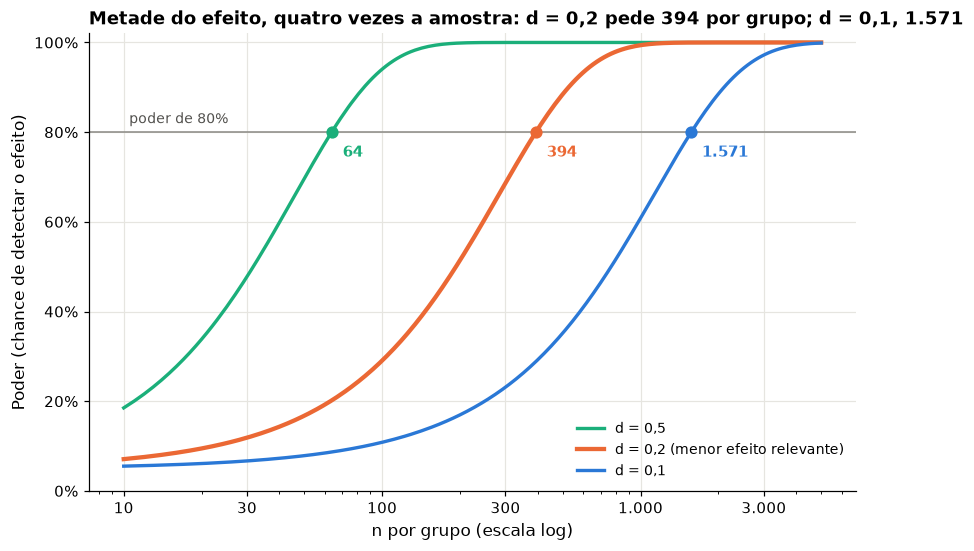

In [40]:
analise_poder = TTestIndPower()
n_ex1 = int(np.ceil(analise_poder.solve_power(effect_size=0.2, alpha=0.05, power=0.80)))
print(f'n por grupo para poder de 80% (d = 0,2; α = 0,05; bilateral): {n_ex1}')

# Curvas de poder: chance de detectar cada tamanho de efeito, conforme o n por grupo
ns_poder = np.unique(np.round(np.logspace(1, np.log10(5000), 200)).astype(int))
fig, ax = plt.subplots(figsize=(9, 5.4))
n_alvos = {}
for d_alvo, cor, lw, rotulo in ((0.5, VERDE, 2.2, 'd = 0,5'), (0.2, LARANJA, 2.8, 'd = 0,2 (menor efeito relevante)'),
                                (0.1, AZUL, 2.2, 'd = 0,1')):
    poder_n = analise_poder.power(effect_size=d_alvo, nobs1=ns_poder, alpha=0.05)
    poder_n = np.where(np.isnan(poder_n), 1.0, poder_n)   # o statsmodels devolve NaN onde o poder já é ≈ 100%
    ax.plot(ns_poder, poder_n, color=cor, lw=lw, label=rotulo)
    n_alvos[d_alvo] = int(np.ceil(analise_poder.solve_power(effect_size=d_alvo, alpha=0.05, power=0.80)))
    ax.plot([n_alvos[d_alvo]], [0.8], 'o', color=cor, ms=7, zorder=4)
    ax.annotate(br(n_alvos[d_alvo], 0), (n_alvos[d_alvo], 0.8), xytext=(7, -16), textcoords='offset points',
                fontsize=10, color=cor, fontweight='bold')
ax.axhline(0.8, color=CINZA, lw=1)
ax.text(10.5, 0.82, 'poder de 80%', fontsize=9, color='#52514e')
ax.set_xscale('log')
ax.set_xticks([10, 30, 100, 300, 1000, 3000], ['10', '30', '100', '300', '1.000', '3.000'])
ax.set_ylim(0, 1.02)
ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0], ['0%', '20%', '40%', '60%', '80%', '100%'])
ax.set_xlabel('n por grupo (escala log)')
ax.set_ylabel('Poder (chance de detectar o efeito)')
ax.set_title(f'Metade do efeito, quatro vezes a amostra: d = 0,2 pede {br(n_alvos[0.2], 0)} por grupo; d = 0,1, {br(n_alvos[0.1], 0)}')
ax.legend(loc='lower right', fontsize=9)
salvar(fig, 'm6_poder_curvas')
plt.show()

**Passo 4 — Sorteio da amostra.** Sorteia-se **separado em cada grupo** (amostra estratificada pelo tipo de escola): assim os dois grupos têm o n planejado, mesmo a privada sendo bem menor na população.

In [41]:
rng = np.random.default_rng(SEMENTE)          # gerador desta seção
a_pub = rng.choice(pop_pub, n_ex1, replace=False)
a_priv = rng.choice(pop_priv, n_ex1, replace=False)
pd.DataFrame({'n': [n_ex1, n_ex1], 'média amostra': [a_pub.mean(), a_priv.mean()], 'dp amostra': [a_pub.std(ddof=1), a_priv.std(ddof=1)],
              'média população': [pop_pub.mean(), pop_priv.mean()], 'dp população': [pop_pub.std(ddof=1), pop_priv.std(ddof=1)]},
             index=['Pública', 'Privada']).round(1)

,n,média amostra,dp amostra,média população,dp população
Pública,394,501.2,110.1,511.2,109.4
Privada,394,636.0,124.1,633.0,121.3


**Passo 5 — Pressupostos.** (a) **Independência:** amostra aleatória, cada participante uma vez. (b) **Normalidade da média:** com n = 394 por grupo, o TCL garante (Módulo 4), mesmo com alguma assimetria. (c) **Variâncias:** o t de **Welch** não exige que sejam iguais, e por isso é o padrão.

Assimetria na amostra: pública = 0,56 | privada = -0,34 (moderada; n grande)
Razão entre as variâncias (maior ÷ menor) = 1,27


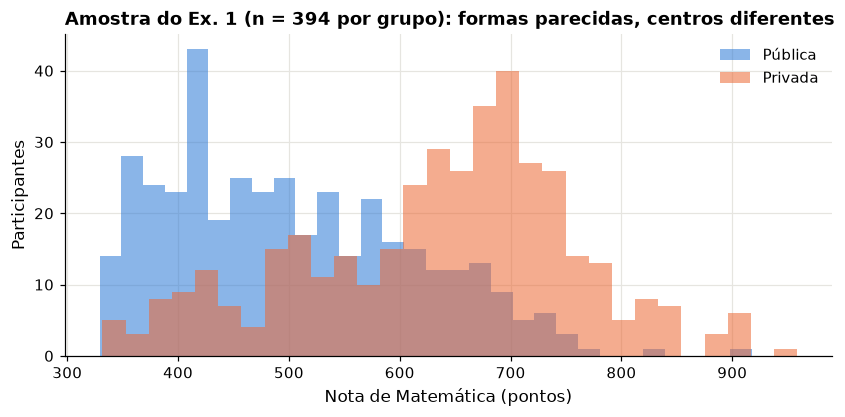

In [42]:
print(f'Assimetria na amostra: pública = {br(stats.skew(a_pub), 2)} | privada = {br(stats.skew(a_priv), 2)} (moderada; n grande)')
print(f'Razão entre as variâncias (maior ÷ menor) = {br(max(a_pub.var(ddof=1), a_priv.var(ddof=1)) / min(a_pub.var(ddof=1), a_priv.var(ddof=1)), 2)}')
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(a_pub, bins=30, alpha=0.55, color=AZUL, label='Pública')
ax.hist(a_priv, bins=30, alpha=0.55, color=LARANJA, label='Privada')
ax.set_xlabel('Nota de Matemática (pontos)'); ax.set_ylabel('Participantes')
ax.set_title(f'Amostra do Ex. 1 (n = {n_ex1} por grupo): formas parecidas, centros diferentes')
ax.legend()
plt.show()

**Passos 6 e 7 — O teste, o efeito, o IC e a leitura de relevância.**

In [43]:
ex1 = comparar(a_priv, a_pub, 'Privadas', 'Públicas')
relatar(ex1)
print(f"Leitura com a margem de ±{br(MARGEM_EX1)} pontos: {classificar(ex1['IC95% inf'], ex1['IC95% sup'], MARGEM_EX1)}")
print(f"Diferença verdadeira na população: {br(pop_priv.mean() - pop_pub.mean())} pontos | "
      f"está no IC da amostra? {ex1['IC95% inf'] <= pop_priv.mean() - pop_pub.mean() <= ex1['IC95% sup']}")

Privadas − Públicas: diferença de 134,8 pontos (IC95% [118,4; 151,2]); d = 1,15 (efeito grande); p < 0,001; n = 394 e 394.
Leitura com a margem de ±23,1 pontos: diferença relevante
Diferença verdadeira na população: 121,8 pontos | está no IC da amostra? True


In [44]:
# Verificação independente: t à mão e controle negativo (rótulos embaralhados)
ep_dif = np.sqrt(a_priv.var(ddof=1) / n_ex1 + a_pub.var(ddof=1) / n_ex1)
print(f"t à mão = diferença ÷ EP = {br(ex1['diferença (A−B)'], 2)} ÷ {br(ep_dif, 2)} = {br(ex1['diferença (A−B)'] / ep_dif, 2)} "
      f"| scipy: {br(ex1['t'], 2)}")
rng = np.random.default_rng(SEMENTE)          # gerador desta seção
notas_ex1 = np.r_[a_priv, a_pub]
p_emb = []
for _ in range(1000):
    g = rng.permutation(len(notas_ex1)) < n_ex1           # metade sorteada como "privada"
    p_emb.append(stats.ttest_ind(notas_ex1[g], notas_ex1[~g], equal_var=False).pvalue)
print(f'Controle negativo: {br(100 * (np.array(p_emb) < 0.05).mean())}% de p < 0,05 com rótulos embaralhados (esperado ≈ 5%)')

t à mão = diferença ÷ EP = 134,77 ÷ 8,36 = 16,13 | scipy: 16,13


Controle negativo: 4,4% de p < 0,05 com rótulos embaralhados (esperado ≈ 5%)


**Passo 8 — Relato.** Na amostra planejada, a média de MT das privadas fica bem acima da das públicas: o IC95% da diferença está **inteiro acima** da margem de relevância (d = 0,2), e o d de Cohen é grande. *Limitações:* compara só concluintes de 2023 que informaram a escola; é observacional, e a diferença mistura renda, capital cultural e seleção de alunos. Não é "o efeito da escola privada" (o Módulo 7 mostra quanto resta com a renda no modelo).

## 6.2 O valor-p cai com n; o efeito não

No Ex. 1 a diferença é grande e qualquer amostra razoável a detecta. O perigo está nas diferenças **pequenas** com n **grande**. Duas lições: (a) a **régua do tamanho do efeito** com a população inteira, em que todas as comparações têm p < 0,001; (b) o mesmo par, com d abaixo do relevante, testado com n crescente.

,n A,n B,diferença (A−B),IC95% inf,IC95% sup,p,d de Cohen,magnitude
comparação,,,,,,,,
MT: privada × pública,219207,783634,121.800,121.237,122.362,0.0,1.086,grande
MT: renda > R$ 6.600 × renda ≤ R$ 1.320,377805,877472,168.476,168.036,168.915,0.0,1.576,grande
MT: homens × mulheres,983373,1585817,46.543,46.228,46.858,0.0,0.379,pequeno
Redação: mulheres × homens,1585817,983373,36.395,35.960,36.831,0.0,0.209,pequeno
MT: brancos × pretos,1119070,301740,77.606,77.155,78.057,0.0,0.629,médio
MT: brancos × pardos,1119070,1062833,62.954,62.631,63.276,0.0,0.517,médio
MT: municipal × estadual,5553,427787,16.282,13.277,19.286,0.0,0.151,desprezível


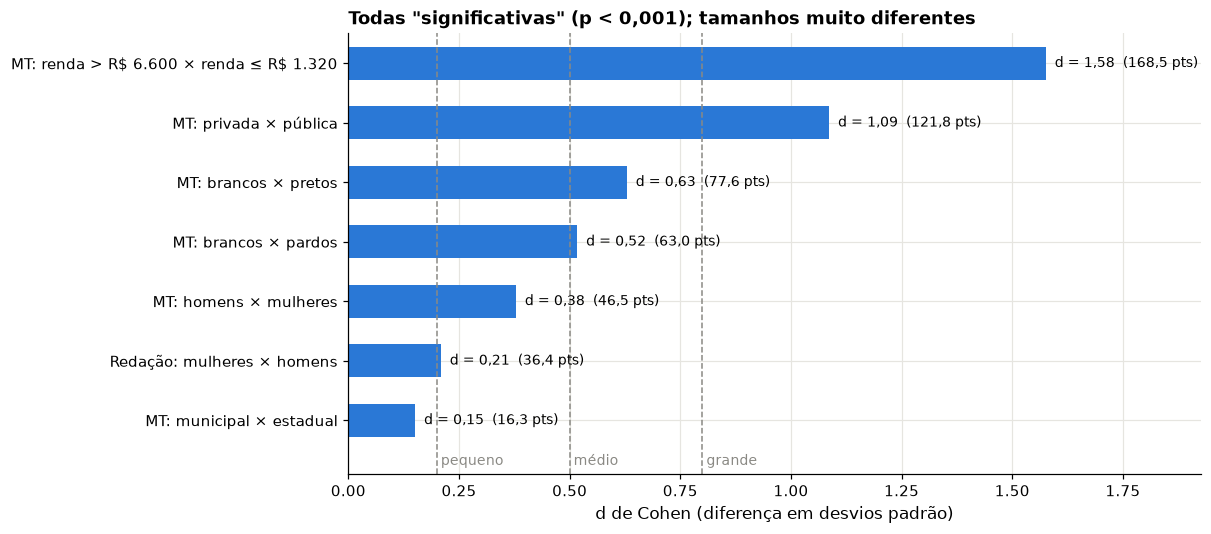

In [45]:
# (a) A régua do tamanho do efeito (população inteira)
renda4 = base.Q006.map(RENDA_4)
mt_dep = {c: base.loc[base.TP_DEPENDENCIA_ADM_ESC == c, 'NU_NOTA_MT'] for c in (1, 2, 3, 4)}
regua = pd.DataFrame([
    comparar(pop_priv, pop_pub, 'MT: privada', 'pública'),
    comparar(base.loc[renda4 == '4) acima de R$ 6.600', 'NU_NOTA_MT'], base.loc[renda4 == '1) até R$ 1.320', 'NU_NOTA_MT'],
             'MT: renda > R$ 6.600', 'renda ≤ R$ 1.320'),
    comparar(base.loc[base.TP_SEXO == 'M', 'NU_NOTA_MT'], base.loc[base.TP_SEXO == 'F', 'NU_NOTA_MT'], 'MT: homens', 'mulheres'),
    comparar(base.loc[base.TP_SEXO == 'F', 'NU_NOTA_REDACAO'], base.loc[base.TP_SEXO == 'M', 'NU_NOTA_REDACAO'], 'Redação: mulheres', 'homens'),
    comparar(base.loc[base.TP_COR_RACA == 1, 'NU_NOTA_MT'], base.loc[base.TP_COR_RACA == 2, 'NU_NOTA_MT'], 'MT: brancos', 'pretos'),
    comparar(base.loc[base.TP_COR_RACA == 1, 'NU_NOTA_MT'], base.loc[base.TP_COR_RACA == 3, 'NU_NOTA_MT'], 'MT: brancos', 'pardos'),
    comparar(mt_dep[3], mt_dep[2], 'MT: municipal', 'estadual'),
])
regua['comparação'] = regua['grupo A'] + ' × ' + regua['grupo B']
display(regua.set_index('comparação')[['n A', 'n B', 'diferença (A−B)', 'IC95% inf', 'IC95% sup', 'p', 'd de Cohen', 'magnitude']].round(3))

ordem = regua.sort_values('d de Cohen')
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.barh(range(len(ordem)), ordem['d de Cohen'], color=AZUL, height=0.55)
ax.set_yticks(range(len(ordem)), [c.replace('$', r'\$') for c in ordem['comparação']])   # "$" em rótulo vira fórmula
for v, lab in ((0.2, 'pequeno'), (0.5, 'médio'), (0.8, 'grande')):
    ax.axvline(v, color=CINZA, lw=1, ls='--')
    ax.text(v, -0.75, f' {lab}', color=CINZA, fontsize=9)
ax.set_ylim(-0.9, len(ordem) - 0.5)
for i, (d, dif) in enumerate(zip(ordem['d de Cohen'], ordem['diferença (A−B)'])):
    ax.text(d + 0.02, i, f'd = {br(d, 2)}  ({br(dif)} pts)', va='center', fontsize=9)
ax.set_xlim(0, max(1.3, ordem['d de Cohen'].max() + 0.35))
ax.set_xlabel('d de Cohen (diferença em desvios padrão)')
ax.set_title('Todas "significativas" (p < 0,001); tamanhos muito diferentes')
salvar(fig, 'm6_regua_efeito')
plt.show()

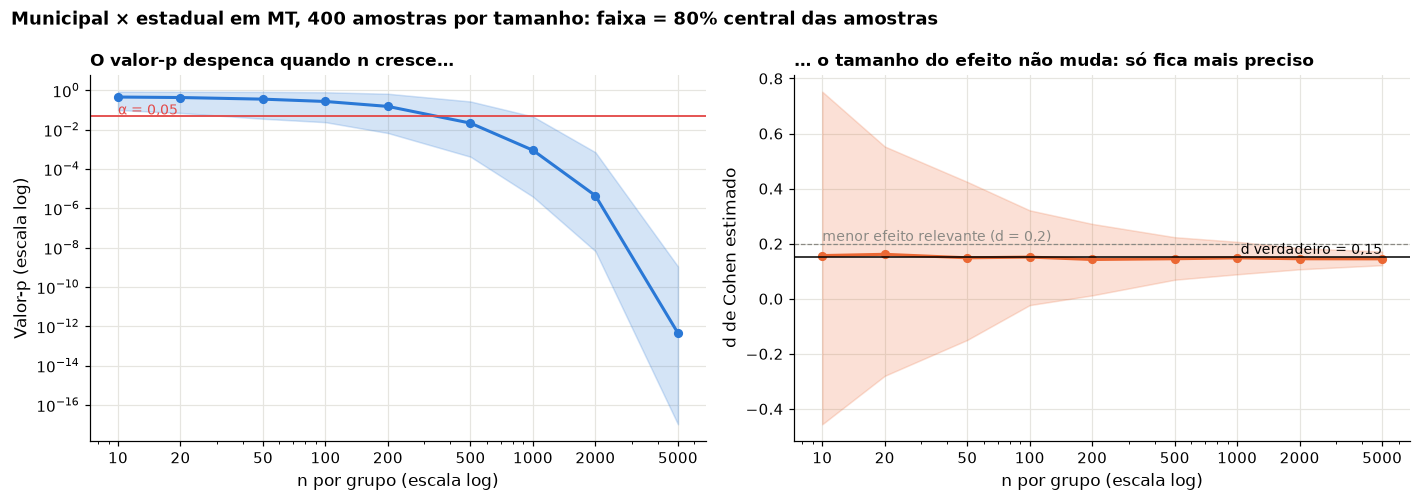

,n por grupo,"% com p < 0,05",p mediano
0,10,3.75,0.460
1,20,7.50,0.435
2,50,13.00,0.360
3,100,17.00,0.274
4,200,29.50,0.154
5,500,64.50,0.022
6,1000,90.25,0.001
7,2000,99.75,0.000
8,5000,100.00,0.000


In [46]:
# (b) Municipal × estadual em MT: d abaixo do relevante; o que acontece com p e d quando n cresce?
rng = np.random.default_rng(SEMENTE)          # gerador desta seção
mun, est = mt_dep[3].to_numpy(), mt_dep[2].to_numpy()
D_MUN_EST = d_cohen(mun, est)
ns = np.array([10, 20, 50, 100, 200, 500, 1000, 2000, 5000])
reps = 400
p_res, d_res, poder = [], [], []
for n in ns:
    A, B = rng.choice(mun, size=(reps, n)), rng.choice(est, size=(reps, n))
    p = stats.ttest_ind(A, B, axis=1, equal_var=False).pvalue
    d = (A.mean(axis=1) - B.mean(axis=1)) / np.sqrt((A.var(axis=1, ddof=1) + B.var(axis=1, ddof=1)) / 2)
    p_res.append(p); d_res.append(d); poder.append(100 * (p < 0.05).mean())
p_res, d_res = np.array(p_res), np.array(d_res)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
ax.fill_between(ns, np.percentile(p_res, 10, axis=1), np.percentile(p_res, 90, axis=1), color=AZUL, alpha=0.2)
ax.plot(ns, np.median(p_res, axis=1), 'o-', color=AZUL, lw=2, ms=5)
ax.axhline(0.05, color=VERMELHO, lw=1.2)
ax.text(ns[0], 0.06, 'α = 0,05', color=VERMELHO, fontsize=9)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xticks(ns, [str(v) for v in ns])
ax.set_xlabel('n por grupo (escala log)'); ax.set_ylabel('Valor-p (escala log)')
ax.set_title('O valor-p despenca quando n cresce…', fontsize=11)
ax = axes[1]
ax.fill_between(ns, np.percentile(d_res, 10, axis=1), np.percentile(d_res, 90, axis=1), color=LARANJA, alpha=0.2)
ax.plot(ns, np.median(d_res, axis=1), 'o-', color=LARANJA, lw=2, ms=5)
ax.axhline(D_MUN_EST, color='black', lw=1)
ax.text(ns[-1], D_MUN_EST, f' d verdadeiro = {br(D_MUN_EST, 2)}', va='bottom', ha='right', fontsize=9)
ax.axhline(0.2, color=CINZA, lw=0.8, ls='--')
ax.text(ns[0], 0.21, 'menor efeito relevante (d = 0,2)', fontsize=9, color=CINZA)
ax.set_xscale('log')
ax.set_xticks(ns, [str(v) for v in ns])
ax.set_xlabel('n por grupo (escala log)'); ax.set_ylabel('d de Cohen estimado')
ax.set_title('… o tamanho do efeito não muda: só fica mais preciso', fontsize=11)
fig.suptitle('Municipal × estadual em MT, 400 amostras por tamanho: faixa = 80% central das amostras', x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
salvar(fig, 'm6_p_vs_d_por_n')
plt.show()
pd.DataFrame({'n por grupo': ns, '% com p < 0,05': poder, 'p mediano': np.median(p_res, axis=1)}).round(3)

**Três lições:** (1) com n pequeno, uma diferença real dá "não significativo" na maioria das amostras: **p > 0,05 não prova igualdade**; (2) com n grande, **tudo** fica significativo, inclusive uma diferença abaixo do relevante (d ≈ 0,15): **significativo e irrelevante**; (3) o d estimado oscila em torno do mesmo valor em qualquer n. Em bases com milhões de linhas, quem decide é o **tamanho do efeito** lido contra a margem.

> **Sobre o pingouin:** a coluna `power` de `pingouin.ttest` é o "poder observado", calculado com o próprio d da amostra: é só outra forma de escrever o valor-p (Hoenig e Heisey, 2001). O poder serve para **planejar** n antes da coleta, como no passo 3.

## 6.3 Ex. 2 — ANOVA: Matemática pelas quatro dependências administrativas

A ANOVA compara **mais de dois grupos** de uma vez: aqui, abre a escola pública em federal, estadual e municipal e compara com a privada. Só para quem tem a dependência informada (seção 2.2: subconjunto não aleatório dos concluintes de 2023).

### IA — Prompt do Ex. 2: ANOVA e Tukey



```text
Papel: Você é um estatístico revisando uma análise para gestores públicos.

Contexto: DataFrame base com a base de análise do ENEM 2023, tratada como população. Colunas: NU_NOTA_MT e TP_DEPENDENCIA_ADM_ESC (1 federal, 2 estadual, 3 municipal, 4 privada; vazia para quem não informou). Vou sortear o mesmo número de participantes em cada dependência, com semente 2023.

Pergunta: A média de MT difere entre as quatro dependências? H0: as quatro médias são iguais; α = 0,05; menor efeito relevante: d = 0,2 entre duas dependências.

Tarefa: (1) Converta d = 0,2 em pontos (DP dentro dos grupos) e calcule o n por grupo com α = 0,05/6 (6 pares; TTestIndPower). (2) Sorteie esse n em cada grupo e cheque as suposições. (3) ANOVA (f_oneway) com a tabela completa: somas de quadrados, g.l., variâncias estimadas, razão F, valor-p e η². (4) Tukey (pairwise_tukeyhsd) com o IC95% de cada par, classificado contra a margem.

Restrições: Não chame de "equivalentes" os pares com p ≥ 0,05. Não calcule de cabeça. Comente em português.

Formato: Tabela ANOVA; tabela de pares com a leitura de cada um; três frases para a diretoria.
```

**Verificação independente** (o analista faz depois de rodar o código da IA):
- Os 4 grupos têm o mesmo n e só códigos 1 a 4
- F refeito à mão: (SQ entre ÷ g.l. entre) ÷ (SQ dentro ÷ g.l. dentro)
- Razão entre a maior e a menor variância abaixo de 4 (regra prática)
- Pares com p ajustado ≥ 0,05 lidos como inconclusivos, salvo se o IC couber inteiro na margem
- Comparar η² da amostra com o da população

**Passo 1 — Pergunta e hipóteses.** H₀: μ(federal) = μ(estadual) = μ(municipal) = μ(privada); H₁: pelo menos uma média difere; α = 0,05. Se a ANOVA rejeitar H₀, o pós-teste de **Tukey** diz **quais** pares diferem.

In [47]:
DEPS = ['Federal', 'Estadual', 'Municipal', 'Privada']
pop_dep = base.loc[base.TP_DEPENDENCIA_ADM_ESC.notna(), ['TP_DEPENDENCIA_ADM_ESC', 'NU_NOTA_MT']].copy()
pop_dep['dependência'] = pop_dep.TP_DEPENDENCIA_ADM_ESC.astype(int).map(ROT_DEPENDENCIA)
pop_dep.groupby('dependência').NU_NOTA_MT.agg(N='count', média='mean', dp='std').loc[DEPS].round(1)

,N,média,dp
dependência,,,
Federal,43273,605.4,117.6
Estadual,427787,510.1,107.7
Municipal,5553,526.4,113.5
Privada,212640,634.7,121.0


**Passo 2 — Margem de relevância.** d = 0,2, o mesmo critério do Ex. 1, convertido em pontos com o desvio padrão **dentro** dos grupos (a variação entre participantes da mesma dependência).

**Passo 3 — Tamanho da amostra.** O Tukey compara os grupos dois a dois: 4 grupos dão **6 pares**. Para não inflar os falsos positivos, o planejamento usa α = 0,05 ÷ 6 em cada par (Bonferroni, um pouco mais exigente que o Tukey) e poder de 80%. Sorteia-se o **mesmo n em cada grupo**, para que a municipal (a menor) não fique com poucos casos.

In [48]:
g_pop = pop_dep.groupby('dependência').NU_NOTA_MT.agg(['count', 'var'])
dp_dentro = np.sqrt(((g_pop['count'] - 1) * g_pop['var']).sum() / (g_pop['count'].sum() - len(g_pop)))
MARGEM_EX2 = 0.2 * dp_dentro
n_pares = len(DEPS) * (len(DEPS) - 1) // 2
alfa_par = 0.05 / n_pares
n_ex2 = int(np.ceil(analise_poder.solve_power(effect_size=0.2, alpha=alfa_par, power=0.80)))
print(f'DP dentro dos grupos = {br(dp_dentro)} pontos → d = 0,2 equivale a ±{br(MARGEM_EX2)} pontos (margem)')
print(f'{n_pares} pares → α por par = 0,05 / {n_pares} = {br(alfa_par, 4)}')
print(f'n por grupo para poder de 80%: {n_ex2} (total de {br(len(DEPS) * n_ex2, 0)}); sem a correção seriam {n_ex1}')

DP dentro dos grupos = 112,6 pontos → d = 0,2 equivale a ±22,5 pontos (margem)
6 pares → α por par = 0,05 / 6 = 0,0083
n por grupo para poder de 80%: 608 (total de 2.432); sem a correção seriam 394


**Por que corrigir o α: quem procura, acha.** Sem efeito nenhum, cada teste a 5% tem 1 chance em 20 de dar "significativo". Com muitas comparações, algum falso positivo aparece quase sempre. Demonstração: 100 testes entre duas metades **sorteadas** de MT (H₀ verdadeira em todos).

In [49]:
rng = np.random.default_rng(SEMENTE)          # gerador desta seção
ps = []
for _ in range(100):
    idx = rng.choice(len(mt), 1000, replace=False)
    ps.append(stats.ttest_ind(mt[idx[:500]], mt[idx[500:]], equal_var=False).pvalue)
ps = np.array(ps)
print(f'p < 0,05 em {(ps < 0.05).sum()} de 100 testes, sem diferença real nenhuma | com Bonferroni (α ÷ 100): {(ps < 0.05 / 100).sum()}')

p < 0,05 em 5 de 100 testes, sem diferença real nenhuma | com Bonferroni (α ÷ 100): 0


**Passo 4 — Sorteio da amostra** (estratificada pela dependência, o mesmo n em cada uma).

In [50]:
amostra_dep = pop_dep.groupby('dependência', group_keys=False).sample(n_ex2, random_state=SEMENTE)
amostra_dep.groupby('dependência').NU_NOTA_MT.agg(n='count', média='mean', dp='std').loc[DEPS].round(1)

,n,média,dp
dependência,,,
Federal,608,604.1,120.9
Estadual,608,514.5,110.9
Municipal,608,524.9,115.5
Privada,608,628.5,121.1


**Passo 5 — Pressupostos.** (a) Independência: amostra aleatória. (b) Forma: com n de centenas por grupo, a média é aproximadamente normal (TCL). (c) Variâncias parecidas: regra prática, a maior até 4 vezes a menor; o teste de Levene é uma conferência formal.

Maior ÷ menor variância = 1,19 (regra prática: até 4)
Levene: p 0,150


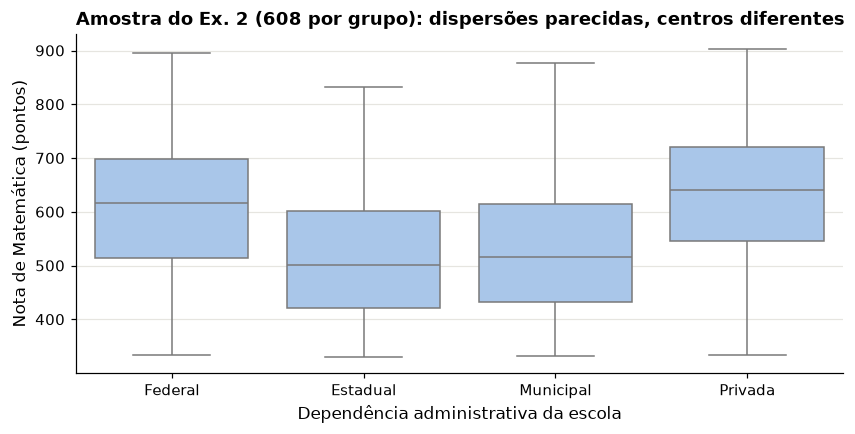

In [51]:
var_g = amostra_dep.groupby('dependência').NU_NOTA_MT.var()
print(f'Maior ÷ menor variância = {br(var_g.max() / var_g.min(), 2)} (regra prática: até 4)')
lev = stats.levene(*[g.to_numpy() for _, g in amostra_dep.groupby('dependência').NU_NOTA_MT])
print(f'Levene: p {fmt_p(lev.pvalue)}')
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=amostra_dep, x='dependência', y='NU_NOTA_MT', order=DEPS, color='#9ec5f4', showfliers=False, ax=ax)
ax.set_xlabel('Dependência administrativa da escola'); ax.set_ylabel('Nota de Matemática (pontos)')
ax.set_title(f'Amostra do Ex. 2 ({n_ex2} por grupo): dispersões parecidas, centros diferentes')
plt.show()

**Passo 6 — A ANOVA**, com a tabela completa.

In [52]:
y_a, g_a = amostra_dep.NU_NOTA_MT, amostra_dep['dependência']
k, N = g_a.nunique(), len(y_a)
grp = y_a.groupby(g_a).agg(['count', 'mean'])
sq_entre = (grp['count'] * (grp['mean'] - y_a.mean()) ** 2).sum()
sq_total = ((y_a - y_a.mean()) ** 2).sum()
sq_dentro = sq_total - sq_entre
F = (sq_entre / (k - 1)) / (sq_dentro / (N - k))
pF = stats.f.sf(F, k - 1, N - k)
tabela_anova = pd.DataFrame({'soma de quadrados': [sq_entre, sq_dentro, sq_total], 'g.l.': [k - 1, N - k, N - 1],
                             'variância estimada': [sq_entre / (k - 1), sq_dentro / (N - k), np.nan],
                             'razão F': [F, np.nan, np.nan]}, index=['entre grupos', 'dentro dos grupos', 'total'])
display(tabela_anova.round(2))
f_scipy = stats.f_oneway(*[g.to_numpy() for _, g in y_a.groupby(g_a)])
print(f'p {fmt_p(pF)} | F crítico (5%) = {br(stats.f.ppf(0.95, k - 1, N - k), 2)} | conferência com scipy: F = {br(f_scipy.statistic, 2)}')
print(f'η² = {br(sq_entre / sq_total, 3)} na amostra | η² na população = {br(eta2(pop_dep.NU_NOTA_MT, pop_dep["dependência"]), 3)}')

,soma de quadrados,g.l.,variância estimada,razão F
entre grupos,5884732.55,3,1961577.52,142.82
dentro dos grupos,33348371.45,2428,13734.91,NaN
total,39233104.00,2431,NaN,NaN


p < 0,001 | F crítico (5%) = 2,61 | conferência com scipy: F = 142,82


η² = 0,150 na amostra | η² na população = 0,210


**Passo 7 — Quais pares diferem, e se importam: Tukey com a margem.** Um par com p ajustado ≥ 0,05 **não** é "equivalente". Para afirmar equivalência, o IC da diferença tem de caber inteiro na margem.

Margem: ±22,5 pontos | meia-largura dos IC de Tukey: 17,3 pontos


,par,meandiff,lower,upper,p-adj,leitura (IC × margem)
0,Estadual × Federal,89.55,72.27,106.83,0.00,diferença relevante
1,Estadual × Municipal,10.37,-6.91,27.65,0.41,inconclusivo
2,Estadual × Privada,113.97,96.69,131.25,0.00,diferença relevante
3,Federal × Municipal,-79.18,-96.46,-61.90,0.00,diferença relevante
4,Federal × Privada,24.42,7.14,41.70,0.00,diferente; relevância incerta
5,Municipal × Privada,103.60,86.32,120.88,0.00,diferença relevante


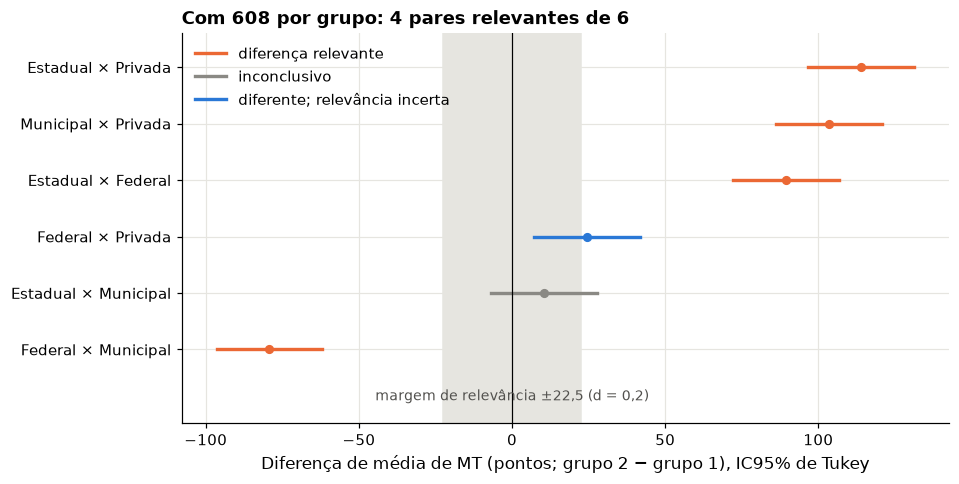

In [53]:
ROTULO = 'leitura (IC × margem)'

def tukey_tabela(df_):
    tk = pairwise_tukeyhsd(df_.NU_NOTA_MT, df_['dependência'], alpha=0.05)
    t = pd.DataFrame(tk.summary().data[1:], columns=tk.summary().data[0])
    t['par'] = t.group1 + ' × ' + t.group2
    t[ROTULO] = [classificar(lo, hi, MARGEM_EX2) for lo, hi in zip(t.lower, t.upper)]
    return t

tk_amostra = tukey_tabela(amostra_dep)
print(f'Margem: ±{br(MARGEM_EX2)} pontos | meia-largura dos IC de Tukey: {br(((tk_amostra.upper - tk_amostra.lower) / 2).mean())} pontos')
display(tk_amostra[['par', 'meandiff', 'lower', 'upper', 'p-adj', ROTULO]].round(2))

fig, ax = plt.subplots(figsize=(9, 4.6))
t = tk_amostra.sort_values('meandiff').reset_index(drop=True)
ax.axvspan(-MARGEM_EX2, MARGEM_EX2, color='#e6e5e0', zorder=0)
ax.text(0, -0.9, f'margem de relevância ±{br(MARGEM_EX2)} (d = 0,2)', ha='center', fontsize=9, color='#52514e')
ax.set_ylim(-1.3, len(t) - 0.4)
cores = {'diferença relevante': LARANJA, 'inconclusivo': CINZA, 'equivalente na prática': VERDE,
         'diferente, mas irrelevante': VERDE, 'diferente; relevância incerta': AZUL}
for i, r in t.iterrows():
    c = cores[r[ROTULO]]
    ax.plot([r.lower, r.upper], [i, i], color=c, lw=2.2)
    ax.plot(r.meandiff, i, 'o', color=c, ms=5)
ax.axvline(0, color='black', lw=0.8)
ax.set_yticks(range(len(t)), t.par)
ax.set_xlabel('Diferença de média de MT (pontos; grupo 2 − grupo 1), IC95% de Tukey')
ax.legend(handles=[plt.Line2D([], [], color=cores[l], lw=2.2, label=l) for l in cores if l in set(t[ROTULO])], loc='upper left')
cont = t[ROTULO].value_counts()
ax.set_title(f'Com {n_ex2} por grupo: {cont.get("diferença relevante", 0)} pares relevantes de {len(t)}')
salvar(fig, 'm6_tukey_margem')
plt.show()

In [54]:
# Contraste: a mesma análise com TODOS os participantes com dependência informada
tk_pop = tukey_tabela(pop_dep)
print(f'n = {br(len(pop_dep), 0)}')
tk_pop[['par', 'meandiff', 'lower', 'upper', 'p-adj', ROTULO]].round(2)

n = 689.253


,par,meandiff,lower,upper,p-adj,leitura (IC × margem)
0,Estadual × Federal,95.31,93.85,96.77,0.0,diferença relevante
1,Estadual × Municipal,16.28,12.37,20.19,0.0,"diferente, mas irrelevante"
2,Estadual × Privada,124.55,123.78,125.32,0.0,diferença relevante
3,Federal × Municipal,-79.03,-83.15,-74.90,0.0,diferença relevante
4,Federal × Privada,29.24,27.71,30.77,0.0,diferença relevante
5,Municipal × Privada,108.27,104.34,112.20,0.0,diferença relevante


In [55]:
# Verificação independente: F à mão e uma diferença do Tukey refeita sem a função
print(f'F = ({br(sq_entre, 0)} / {k - 1}) ÷ ({br(sq_dentro, 0)} / {N - k}) = {br((sq_entre / (k - 1)) / (sq_dentro / (N - k)), 2)}')
print('Códigos sorteados:', sorted(amostra_dep.TP_DEPENDENCIA_ADM_ESC.astype(int).unique().tolist()), '| n por grupo:',
      amostra_dep['dependência'].value_counts().unique().tolist())
med = amostra_dep.groupby('dependência').NU_NOTA_MT.mean()
print(f"Privada − Federal, à mão: {br(med['Privada'] - med['Federal'], 2)} | Tukey: "
      f"{br(tk_amostra.loc[tk_amostra.par == 'Federal × Privada', 'meandiff'].iloc[0], 2)}")

F = (5.884.733 / 3) ÷ (33.348.371 / 2428) = 142,82
Códigos sorteados: [1, 2, 3, 4] | n por grupo: [608]
Privada − Federal, à mão: 24,42 | Tukey: 24,42


**Passo 8 — Relato.** A ANOVA rejeita H₀ com folga, e a dependência está associada a uma parte considerável da variação de MT (η² de 0,15 na amostra e 0,21 na população); ainda assim, a maior parte da variação está **dentro** de cada tipo de escola. No Tukey, lido contra a margem de ±22,5 pontos (d = 0,2):
- **Federal e privada** ficam bem acima de **estadual e municipal**: os quatro pares são diferenças relevantes.
- **Federal × privada:** a privada fica acima, mas o IC da amostra cruza a margem (relevância incerta); na população, a diferença (≈ 29 pontos) passa da margem.
- **Estadual × municipal:** inconclusivo na amostra; na população, diferente mas **irrelevante** (≈ 16 pontos, dentro da margem). O n foi planejado para *detectar* d = 0,2, não para *provar* equivalência.

*Limitações:* só concluintes de 2023 com a dependência informada (subconjunto não aleatório); comparação observacional; a municipal tem poucos alunos no ensino médio, e generalizar para "as escolas municipais" exige cuidado.

## 6.4 Ex. 3 — Qui-quadrado: escolaridade do pai × renda familiar

Duas variáveis **categóricas**, por isso o teste é outro: o qui-quadrado compara a tabela observada com a esperada se não houvesse associação. Usa **todos os inscritos** (a escolaridade do pai e a renda não dependem da presença na prova), sem quem respondeu "Não sei" sobre o pai.

### IA — Prompt do Ex. 3: o qui-quadrado



```text
Papel: Você é um estatístico revisando uma análise para gestores públicos.

Contexto: DataFrame insc com todos os inscritos do ENEM 2023. Q001 = escolaridade do pai (A a G; H = "Não sei"); Q006 = renda familiar em 17 faixas (A a Q).

Pergunta: A escolaridade do pai e a renda familiar estão associadas? H0: independência; α = 0,05; menor efeito relevante: V de Cramér = 0,1.

Tarefa: (1) Exclua "Não sei"; agrupe Q001 em 5 níveis (A–C fund. incompleto; D fund.; E médio; F superior; G pós) e Q006 em 4 faixas (A–B; C–E; F–H; I–Q). (2) Qui-quadrado (scipy.stats.chi2_contingency): χ², g.l., valor-p e menor esperada; V de Cramér; % por linha num mapa de calor. (3) Planeje a amostra: n para V = 0,1 com poder de 80% (GofChisquarePower, w = V × √3, 12 g.l.) e n para esperadas ≥ 5; use o maior. (4) Repita o teste nessa amostra (semente 2023); se alguma esperada ficar < 5, dê também o p por permutação.

Restrições: Confira que todas as frequências esperadas são ≥ 5. Nada de linguagem causal. Só código.

Formato: Tabelas; mapa de calor; como ler χ², valor-p e V na população e na amostra.
```

**Verificação independente** (o analista faz depois de rodar o código da IA):
- g.l. = (5 − 1) × (4 − 1) = 12
- Uma esperada à mão: total da linha × total da coluna ÷ total geral
- O V quase não muda entre população e amostra; o χ² cai muito
- Usar o V como se fosse o w daria um n bem maior (erro comum)

**Passo 1 — Pergunta e hipóteses.** H₀: escolaridade do pai e renda são independentes; H₁: estão associadas; α = 0,05. Primeiro, a "verdade" na população.

População (n = 3.530.429): χ² = 1.199.953; gl = 12; p < 0,001; menor esperada = 32.708; V = 0,337


renda,1) até R$ 1.320,2) R$ 1.320–3.300,3) R$ 3.300–6.600,4) acima de R$ 6.600
instr_pai,,,,
1) Fund. incompleto,765306,486049,105437,31308
2) Fund. completo,172624,182948,59716,22851
3) Médio completo,317873,452303,226172,117816
4) Superior completo,32670,84021,91329,125961
5) Pós-graduação,13605,35791,53594,153055


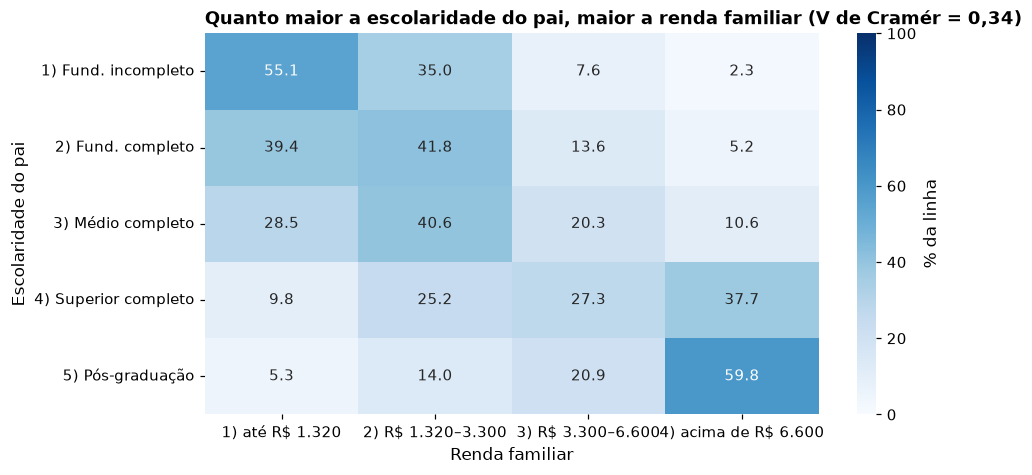

In [56]:
INSTR_5 = {**dict.fromkeys('ABC', '1) Fund. incompleto'), 'D': '2) Fund. completo', 'E': '3) Médio completo',
           'F': '4) Superior completo', 'G': '5) Pós-graduação'}
qq = insc.loc[insc.Q001 != 'H', ['Q001', 'Q006']].copy()
qq['instr_pai'] = qq.Q001.map(INSTR_5)
qq['renda'] = qq.Q006.map(RENDA_4)
tab = pd.crosstab(qq.instr_pai, qq.renda)
chi2, p, gl, esperado = stats.chi2_contingency(tab)
V = stats.contingency.association(tab.to_numpy(), method='cramer')
print(f'População (n = {br(len(qq), 0)}): χ² = {br(chi2, 0)}; gl = {gl}; p {fmt_p(p)}; menor esperada = {br(esperado.min(), 0)}; V = {br(V, 3)}')
display(tab)

pct = pd.crosstab(qq.instr_pai, qq.renda, normalize='index') * 100
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(pct, annot=True, fmt='.1f', cmap='Blues', vmin=0, vmax=100, cbar_kws={'label': '% da linha'}, ax=ax)
ax.set_xlabel('Renda familiar'); ax.set_ylabel('Escolaridade do pai')
ax.tick_params(axis='x', rotation=0)
ax.set_title(f'Quanto maior a escolaridade do pai, maior a renda familiar (V de Cramér = {br(V, 2)})')
salvar(fig, 'm6_quiquadrado_pai_renda')
plt.show()

**Passo 2 — Margem de relevância: V de Cramér = 0,1.** O V vai de 0 (nenhuma associação) a 1 (associação total); abaixo de 0,1 a associação seria fraca demais para orientar decisão.

**Passo 3 — Tamanho da amostra.** A função de poder (`GofChisquarePower`) recebe o **w de Cohen**, ligado ao V por w = V × √(min(linhas, colunas) − 1). Na tabela 5 × 4, w = 0,1 × √3 ≈ 0,17, com 12 g.l. (a função os recebe como `n_bins` = gl + 1). Duas condições: (1) poder de 80%; (2) frequências esperadas ≥ 5 em todas as caselas (BAR cap. 12, p. 250–251). O n planejado é o **maior** dos dois.

In [57]:
V_MIN = 0.1
LINHAS, COLUNAS = tab.shape
GL_TAB = (LINHAS - 1) * (COLUNAS - 1)
W_MIN = V_MIN * np.sqrt(min(LINHAS, COLUNAS) - 1)
n_poder = int(np.ceil(GofChisquarePower().solve_power(effect_size=W_MIN, n_bins=GL_TAB + 1, alpha=0.05, power=0.80)))
p_casela_min = np.outer(tab.sum(axis=1), tab.sum(axis=0)).min() / tab.to_numpy().sum() ** 2
n_esperadas = int(np.ceil(5 / p_casela_min))
n_ex3 = max(n_poder, n_esperadas)
print(f'V = {br(V_MIN)} em tabela {LINHAS} × {COLUNAS} → w = {br(W_MIN, 3)}; gl = {GL_TAB}')
print(f'(1) Poder de 80%: n = {n_poder} | (2) Esperadas ≥ 5: casela mais rara com {br(100 * p_casela_min, 2)}% → n ≥ {n_esperadas}')
print(f'n planejado = {n_ex3}')
n_erro_w = int(np.ceil(GofChisquarePower().solve_power(effect_size=V_MIN, n_bins=GL_TAB + 1, alpha=0.05, power=0.80)))
print(f'Erro comum: usar V = {br(V_MIN)} como se fosse o w daria n = {br(n_erro_w, 0)}, em vez de {n_poder}')

V = 0,1 em tabela 5 × 4 → w = 0,173; gl = 12
(1) Poder de 80%: n = 578 | (2) Esperadas ≥ 5: casela mais rara com 0,93% → n ≥ 540
n planejado = 578
Erro comum: usar V = 0,1 como se fosse o w daria n = 1.734, em vez de 578


**Passos 4 a 7 — Sorteio, pressupostos, teste e tamanho do efeito.** O pressuposto do qui-quadrado é **esperadas ≥ 5**; se falhar na amostra, o valor-p sai por **permutação** (embaralhar a renda mantendo os totais), que não depende dessa condição.

In [58]:
sub = qq.sample(n_ex3, random_state=SEMENTE)
tab_s = pd.crosstab(sub.instr_pai, sub.renda)
c2s, ps, gls, es = stats.chi2_contingency(tab_s)
V_s = stats.contingency.association(tab_s.to_numpy(), method='cramer')
print(f'Amostra n = {n_ex3}: χ² = {br(c2s, 1)}; gl = {gls}; p {fmt_p(ps)}; V = {br(V_s, 3)}; '
      f'menor esperada = {br(es.min(), 1)}; caselas com esperada < 5: {(es < 5).sum()} de {es.size}')
if (es < 5).any():
    rng = np.random.default_rng(SEMENTE)      # gerador desta seção
    renda_s = sub.renda.to_numpy()
    c2_perm = np.array([stats.chi2_contingency(pd.crosstab(sub.instr_pai.to_numpy(), rng.permutation(renda_s)))[0]
                        for _ in range(2000)])
    print(f'p por permutação (2.000 repetições) = {br((1 + (c2_perm >= c2s).sum()) / 2001, 4)}')
display(tab_s)

Amostra n = 578: χ² = 178,0; gl = 12; p < 0,001; V = 0,320; menor esperada = 4,8; caselas com esperada < 5: 2 de 20


p por permutação (2.000 repetições) = 0,0005


renda,1) até R$ 1.320,2) R$ 1.320–3.300,3) R$ 3.300–6.600,4) acima de R$ 6.600
instr_pai,,,,
1) Fund. incompleto,138,83,17,6
2) Fund. completo,23,29,16,6
3) Médio completo,54,73,33,16
4) Superior completo,3,12,11,16
5) Pós-graduação,3,8,9,22


In [59]:
# Verificação independente: uma frequência esperada à mão e o g.l.
lin, col = '5) Pós-graduação', '1) até R$ 1.320'
e_mao = tab.loc[lin].sum() * tab[col].sum() / tab.to_numpy().sum()
print(f'Esperada ({lin}; {col}) à mão = {br(e_mao, 1)} | chi2_contingency = {br(esperado[tab.index.get_loc(lin), tab.columns.get_loc(col)], 1)}')
print(f'g.l. = ({LINHAS} − 1) × ({COLUNAS} − 1) = {GL_TAB} | scipy: {gl}')

Esperada (5) Pós-graduação; 1) até R$ 1.320) à mão = 94.433,4 | chi2_contingency = 94.433,4
g.l. = (5 − 1) × (4 − 1) = 12 | scipy: 12


**Passo 8 — Relato.** A associação entre escolaridade do pai e renda familiar é **moderada** (V bem acima do mínimo relevante de 0,1), na população e na amostra planejada. O χ² cai muito da população para a amostra, porque **cresce com n**; o V quase não muda: é ele que mede a **força**. *Limitações:* respostas autodeclaradas do questionário; "Não sei" excluído (cerca de 10% dos inscritos); associação, não causa.

In [60]:
# Mesma lógica, outra tabela: presença em MT × renda (todos os inscritos), a origem do viés de seleção (Módulo 5)
tab_pres = pd.crosstab(insc.Q006.map(RENDA_4), insc.TP_PRESENCA_MT == 1).rename(columns={False: 'não presentes', True: 'presentes'})
c2p, pp_, glp, _ = stats.chi2_contingency(tab_pres)
V_pres = stats.contingency.association(tab_pres.to_numpy(), method='cramer')
print(f'χ² = {br(c2p, 0)}; gl = {glp}; p {fmt_p(pp_)}; V de Cramér = {br(V_pres, 3)}')
tab_pres['% presentes'] = 100 * tab_pres.presentes / tab_pres[['não presentes', 'presentes']].sum(axis=1)
tab_pres.round(1)

χ² = 95.031; gl = 3; p < 0,001; V de Cramér = 0,155


TP_PRESENCA_MT,não presentes,presentes,% presentes
Q006,,,
1) até R$ 1.320,573015,940309,62.1
2) R$ 1.320–3.300,458316,923986,66.8
3) R$ 3.300–6.600,130667,441283,77.2
4) acima de R$ 6.600,79530,386849,82.9


---
# Módulo 7 — Correlação e regressão

> *"Correlação resume a força de uma relação linear; regressão transforma essa relação numa equação. Nenhuma das duas, sozinha, prova causa."*

## 7.1 Correlação entre as notas e o tamanho da amostra

### IA — Prompt da correlação



```text
Papel: Você é um estatístico que mede relações entre variáveis quantitativas.

Contexto: DataFrame base com a base de análise do ENEM 2023 e as cinco notas (NU_NOTA_CN, NU_NOTA_CH, NU_NOTA_LC, NU_NOTA_MT, NU_NOTA_REDACAO).

Pergunta: Quão fortemente as notas andam juntas? E quanto o r de uma amostra pequena pode se afastar do r verdadeiro?

Tarefa: (1) Matriz de correlação de Pearson das cinco notas, num mapa de calor. (2) Spearman de CN × MT. (3) Para n = 10, 30, 100 e 1.000, sorteie 1.000 amostras (semente 2023), calcule o r de CN × MT em cada uma e mostre o intervalo onde caem 95% dos r.

Restrições: Não interprete correlação como causa. Vetorize o cálculo do r. Só código.

Formato: Código comentado; depois, uma frase sobre o que um r = 0,7 com n = 10 permite afirmar.
```

**Verificação independente** (o analista faz depois de rodar o código da IA):
- Diagonal da matriz = 1 e matriz simétrica
- O r vetorizado bate com np.corrcoef numa amostra
- Com n = 10, o intervalo de 95% dos r é muito largo

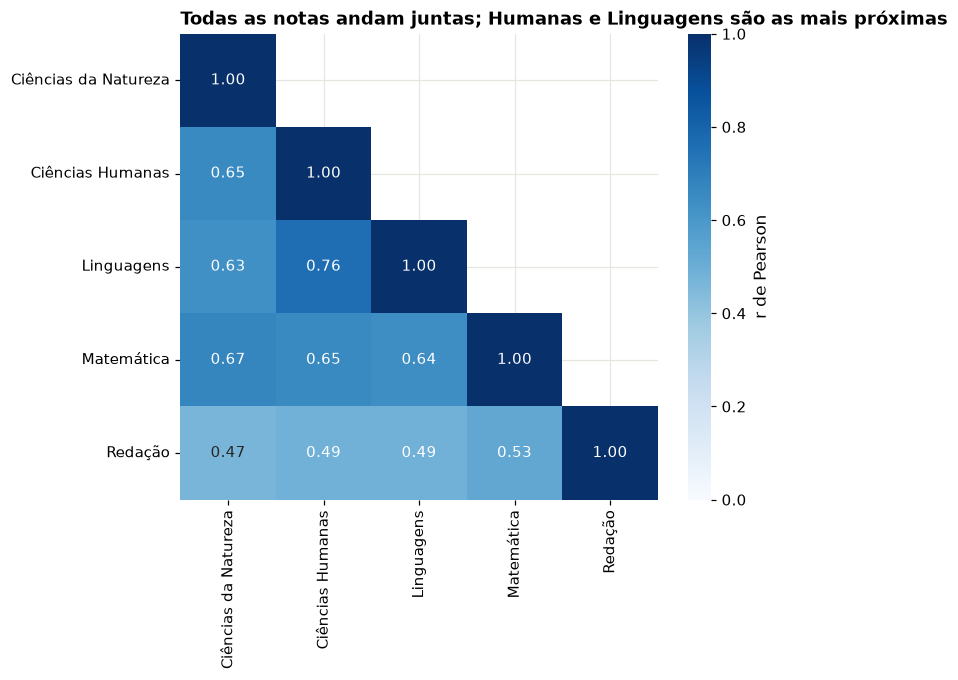

CN × MT: Pearson r = 0,674 | Spearman (300 mil pares sorteados) = 0,638


In [61]:
corr = base[NOTAS].rename(columns=NOME_NOTA).corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues', mask=mask, vmin=0, vmax=1, ax=ax, cbar_kws={'label': 'r de Pearson'})
ax.set_title('Todas as notas andam juntas; Humanas e Linguagens são as mais próximas')
salvar(fig, 'm7_correlacao_notas')
plt.show()

cn, mtv = base.NU_NOTA_CN.to_numpy(), base.NU_NOTA_MT.to_numpy()
r_pop = np.corrcoef(cn, mtv)[0, 1]
rng = np.random.default_rng(SEMENTE)          # gerador desta seção
idx = rng.choice(len(cn), 300_000, replace=False)
print(f'CN × MT: Pearson r = {br(r_pop, 3)} | Spearman (300 mil pares sorteados) = {br(stats.spearmanr(cn[idx], mtv[idx]).statistic, 3)}')

In [62]:
# Correlação em amostras pequenas: 1.000 amostras por n
rng = np.random.default_rng(SEMENTE)          # gerador desta seção
linhas = []
for n in (10, 30, 100, 1000):
    ii = rng.integers(0, len(cn), size=(1000, n))
    X, Y = cn[ii], mtv[ii]
    Xc, Yc = X - X.mean(axis=1, keepdims=True), Y - Y.mean(axis=1, keepdims=True)
    r = (Xc * Yc).sum(axis=1) / np.sqrt((Xc ** 2).sum(axis=1) * (Yc ** 2).sum(axis=1))
    linhas.append({'n': n, 'r mediano': np.median(r), 'r (2,5%)': np.percentile(r, 2.5), 'r (97,5%)': np.percentile(r, 97.5)})
print(f'Verificação: r vetorizado da última amostra = {br(r[-1], 4)} | np.corrcoef = {br(np.corrcoef(X[-1], Y[-1])[0, 1], 4)}')
print(f'Variação de r em 1.000 amostras (r verdadeiro = {br(r_pop, 3)}):')
pd.DataFrame(linhas).set_index('n').round(2)

Verificação: r vetorizado da última amostra = 0,6768 | np.corrcoef = 0,6768
Variação de r em 1.000 amostras (r verdadeiro = 0,674):


,r mediano,"r (2,5%)","r (97,5%)"
n,,,
10,0.69,0.05,0.93
30,0.67,0.39,0.84
100,0.67,0.53,0.78
1000,0.68,0.63,0.71


## 7.2 Regressão simples: MT ~ CN, e o diagnóstico que o R² não mostra

### IA — Prompt da regressão simples



```text
Papel: Você é um estatístico revisando uma análise para gestores públicos.

Contexto: Arrays cn e mtv com as notas de CN e MT da base de análise do ENEM 2023 (2,57 milhões de pares). Exemplo conceitual: a nota de CN não "causa" a de MT.

Pergunta: Quanto MT acompanha CN, e a reta é um bom resumo dessa relação?

Tarefa: (1) Ajuste MT ~ CN por mínimos quadrados (statsmodels OLS): intercepto, inclinação com IC95%, R² e erro padrão residual. (2) Preveja MT para CN = 500 e CN = 700, com o erro típico. (3) Diagnóstico: resíduo médio e DP do resíduo por faixa de CN, em gráfico. (4) Reproduza o quarteto de Anscombe (1973) e mostre que os quatro conjuntos têm a mesma média, r e reta.

Restrições: Não use linguagem causal. Não confie no R² sem olhar os resíduos. Só código.

Formato: Código comentado; depois, o que o gráfico de resíduos mostra que o R² não mostra.
```

**Verificação independente** (o analista faz depois de rodar o código da IA):
- Inclinação = r × s_y / s_x (conta à mão)
- R² = r² na regressão simples
- Resíduos com média zero no total
- Anscombe: r ≈ 0,82 e reta y = 3 + 0,5x nos quatro conjuntos

In [63]:
modelo_cn = sm.OLS(mtv, sm.add_constant(cn)).fit()
b0, b1 = modelo_cn.params
ic_b1 = modelo_cn.conf_int()[1]
rse = np.sqrt(modelo_cn.scale)
print(f'MT = {br(b0, 2)} + {br(b1, 3)} × CN | R² = {br(modelo_cn.rsquared, 3)} | erro padrão residual = {br(rse)} pontos')
print(f'IC95% da inclinação = [{br(ic_b1[0], 3)}; {br(ic_b1[1], 3)}]')
print(f'Previsão para CN = 500: {br(b0 + b1 * 500)} | CN = 700: {br(b0 + b1 * 700)} (erro típico ±{br(rse, 0)})')
print(f'Verificação: r·s_y/s_x = {br(r_pop * mtv.std() / cn.std(), 3)} | r² = {br(r_pop ** 2, 3)} | média dos resíduos = {br(modelo_cn.resid.mean(), 6)}')

MT = 5,03 + 1,069 × CN | R² = 0,455 | erro padrão residual = 92,3 pontos
IC95% da inclinação = [1,068; 1,071]
Previsão para CN = 500: 539,6 | CN = 700: 753,4 (erro típico ±92)
Verificação: r·s_y/s_x = 1,069 | r² = 0,455 | média dos resíduos = 0,000000


,count,mean,std
faixa de CN,,,
"(0, 400]",243571,39.8,87.1
"(400, 450]",470798,-0.5,85.7
"(450, 500]",608434,-14.6,93.0
"(500, 550]",570037,-15.5,97.3
"(550, 600]",409593,-1.1,93.5
"(600, 650]",170934,26.9,77.8
"(650, 1000]",95823,43.0,59.7


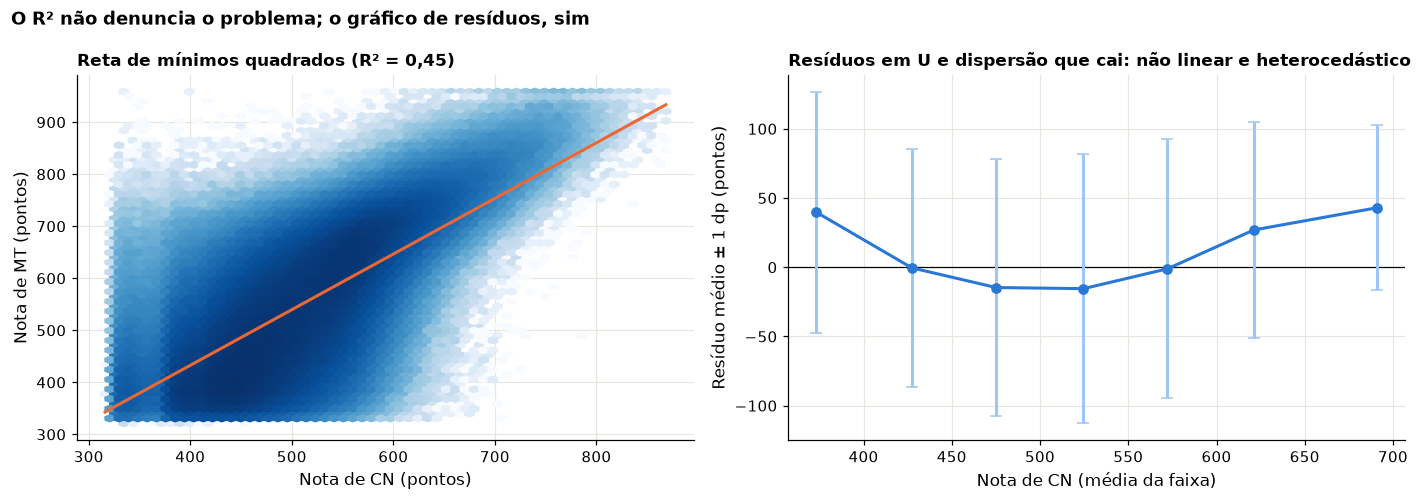

In [64]:
residuos = modelo_cn.resid
faixas_cn = pd.cut(cn, [0, 400, 450, 500, 550, 600, 650, 1000])
diag = pd.DataFrame({'faixa de CN': faixas_cn, 'resíduo': residuos}).groupby('faixa de CN', observed=True).resíduo.agg(['count', 'mean', 'std'])
display(diag.round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
ax.hexbin(cn, mtv, gridsize=60, cmap='Blues', bins='log', mincnt=1)
xs = np.array([cn.min(), cn.max()])
ax.plot(xs, b0 + b1 * xs, color=LARANJA, lw=2)
ax.set_xlabel('Nota de CN (pontos)'); ax.set_ylabel('Nota de MT (pontos)')
ax.set_title(f'Reta de mínimos quadrados (R² = {br(modelo_cn.rsquared, 2)})', fontsize=11)
ax = axes[1]
centros = pd.Series(cn).groupby(faixas_cn, observed=True).mean().to_numpy()
ax.axhline(0, color='black', lw=0.8)
ax.errorbar(centros, diag['mean'], yerr=diag['std'], fmt='o-', color=AZUL, ecolor='#9ec5f4', capsize=4, lw=2)
ax.set_xlabel('Nota de CN (média da faixa)'); ax.set_ylabel('Resíduo médio ± 1 dp (pontos)')
ax.set_title('Resíduos em U e dispersão que cai: não linear e heterocedástico', fontsize=11)
fig.suptitle('O R² não denuncia o problema; o gráfico de resíduos, sim', x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
salvar(fig, 'm7_residuos_mt_cn')
plt.show()

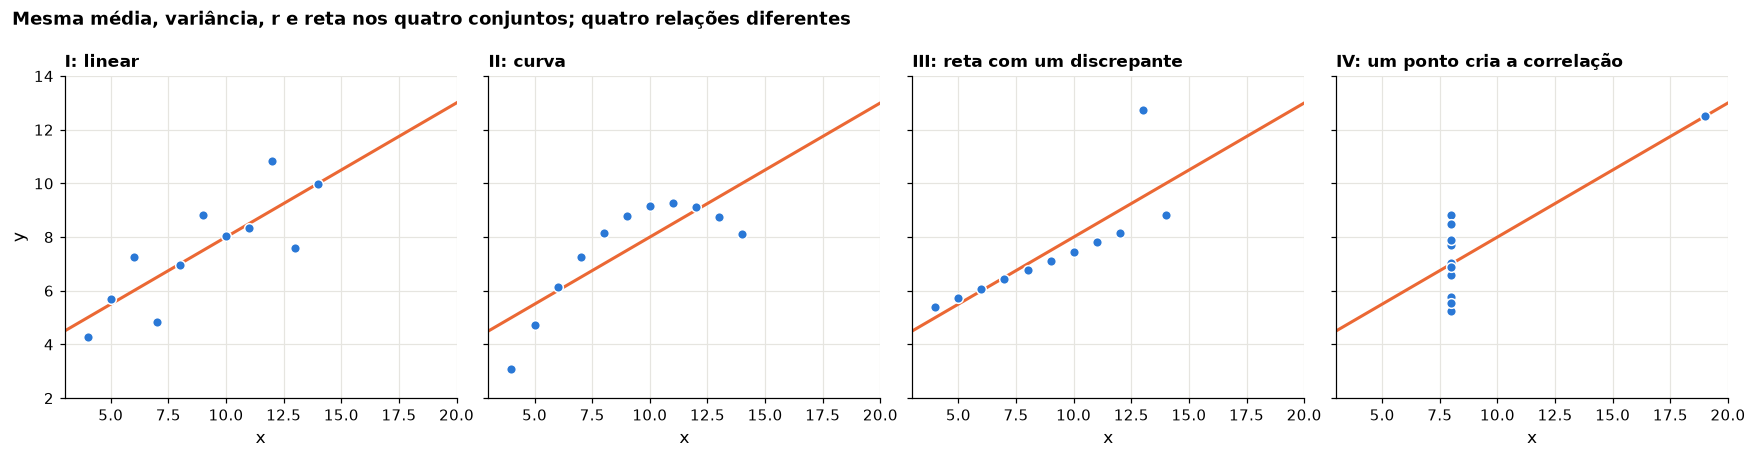

,média x,média y,variância y,r,intercepto,inclinação
I: linear,9.0,7.501,4.127,0.816,3.000,0.5
II: curva,9.0,7.501,4.128,0.816,3.001,0.5
III: reta com um discrepante,9.0,7.500,4.123,0.816,3.002,0.5
IV: um ponto cria a correlação,9.0,7.501,4.123,0.817,3.002,0.5


In [65]:
# Quarteto de Anscombe (1973), The American Statistician 27(1):17–21
X_ANS = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
ANSCOMBE = {
    'I: linear':                      (X_ANS, [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]),
    'II: curva':                      (X_ANS, [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]),
    'III: reta com um discrepante':   (X_ANS, [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]),
    'IV: um ponto cria a correlação': ([8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8], [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]),
}
linhas = {}
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), sharex=True, sharey=True)
xs = np.array([3, 20])
for ax, (nome, (x, y)) in zip(axes, ANSCOMBE.items()):
    x, y = np.array(x, dtype=float), np.array(y)
    a1, a0 = np.polyfit(x, y, 1)
    linhas[nome] = {'média x': x.mean(), 'média y': y.mean(), 'variância y': y.var(ddof=1),
                    'r': np.corrcoef(x, y)[0, 1], 'intercepto': a0, 'inclinação': a1}
    ax.plot(xs, a0 + a1 * xs, color=LARANJA, lw=2)
    ax.scatter(x, y, s=40, color=AZUL, edgecolor='white', linewidth=1, zorder=3)
    ax.set_title(nome, fontsize=11)
    ax.set_xlabel('x')
axes[0].set_ylabel('y')
axes[0].set_xlim(3, 20); axes[0].set_ylim(2, 14)
fig.suptitle('Mesma média, variância, r e reta nos quatro conjuntos; quatro relações diferentes', x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
salvar(fig, 'm7_anscombe')
plt.show()
pd.DataFrame(linhas).T.round(3)

**Leitura:** a reta resume bem a tendência (MT sobe cerca de 1 ponto por ponto de CN), mas prevê a **média**, não o aluno: o erro típico é de ±92 pontos. Os resíduos em U e a dispersão que cai mostram que a relação não é bem linear, e o R² não avisa. Anscombe mostra o mesmo em quatro gráficos: o resumo não substitui o gráfico.

## 7.3 Regressão múltipla: o que permanece quando controlamos os outros fatores

A pergunta do módulo: quanto de cada fator (renda, escola, sexo, cor/raça) **permanece** quando os outros entram no modelo? Isso é controle de **confundimento observado**: o que não foi medido continua lá.

### IA — Prompt da regressão múltipla



```text
Papel: Você é um estatístico revisando uma análise para gestores públicos.

Contexto: DataFrame conc com os concluintes de 2023 que informaram escola (base de análise do ENEM 2023, cerca de 1 milhão). Colunas: NU_NOTA_MT; Q006 (renda, 17 faixas ordinais A–Q); TP_ESCOLA (2 pública, 3 privada); TP_SEXO (M, F); TP_COR_RACA (0 não declarada, 1 branca, 2 preta, 3 parda, 4 amarela, 5 indígena). Dados observacionais.

Pergunta: Quanto da variação de MT está associada à renda, ao tipo de escola, ao sexo e à cor/raça, cada uma mantidas as outras constantes?

Tarefa: (1) Proponha a codificação: renda como código 1–17 (diga o que isso supõe); escola, sexo e cor/raça como indicadoras 0/1, com "branca" como referência. (2) Ajuste com statsmodels (OLS) cinco modelos: só cor/raça; só renda; + escola; + sexo; + cor/raça. (3) Tabela com coeficientes, IC95% e R² de cada modelo. (4) Diagnóstico: resíduos × ajustados e VIF.

Restrições: Não use "efeito" nem "causa". Diga que variáveis importantes ficaram de fora. Só código, sem números.

Formato: Modelos lado a lado; diagnóstico; quatro frases de interpretação em linguagem de associação.
```

**Verificação independente** (o analista faz depois de rodar o código da IA):
- n = nº de concluintes de 2023 com TP_ESCOLA 2 ou 3 na base de análise
- Coeficiente da renda cai quando a escola entra (renda e escola andam juntas)
- Cor/raça como indicadoras, nunca como número 0–6
- VIF abaixo de 10
- Texto: "diferença que permanece", não "efeito da cor"

In [66]:
conc = base[base.TP_ESCOLA.isin([2, 3])].copy()          # concluintes de 2023 que informaram escola
conc['renda'] = conc.Q006.map({c: i + 1 for i, c in enumerate(FAIXAS_RENDA)})
conc['privada'] = (conc.TP_ESCOLA == 3).astype(int)
conc['mulher'] = (conc.TP_SEXO == 'F').astype(int)
# Cor/raça autodeclarada: indicadoras 0/1, com "Branca" (o maior grupo) como referência
conc['preta'] = (conc.TP_COR_RACA == 2).astype(int)
conc['parda'] = (conc.TP_COR_RACA == 3).astype(int)
conc['indígena'] = (conc.TP_COR_RACA == 5).astype(int)
conc['amarela ou não decl.'] = conc.TP_COR_RACA.isin([0, 4]).astype(int)
COR_VARS = ['preta', 'parda', 'indígena', 'amarela ou não decl.']

def nome_modelo(vars_):
    partes = [v for v in vars_ if v not in COR_VARS] + (['cor/raça'] if set(COR_VARS) <= set(vars_) else [])
    return 'MT ~ ' + ' + '.join(partes)

linhas, modelos = [], {}
for vars_ in (COR_VARS, ['renda'], ['renda', 'privada'], ['renda', 'privada', 'mulher'], ['renda', 'privada', 'mulher'] + COR_VARS):
    mo = sm.OLS(conc.NU_NOTA_MT, sm.add_constant(conc[vars_])).fit()
    modelos[nome_modelo(vars_)] = mo
    linhas.append({'modelo': nome_modelo(vars_), **{v: mo.params[v] for v in vars_}, 'R²': mo.rsquared})
print('n =', br(len(conc), 0))
pd.DataFrame(linhas).set_index('modelo')[['renda', 'privada', 'mulher'] + COR_VARS + ['R²']].round(3)

n = 1.002.841


,renda,privada,mulher,preta,parda,indígena,amarela ou não decl.,R²
modelo,,,,,,,,
MT ~ cor/raça,NaN,NaN,NaN,-73.352,-61.847,-103.185,-37.176,0.068
MT ~ renda,15.688,NaN,NaN,NaN,NaN,NaN,NaN,0.228
MT ~ renda + privada,11.881,60.585,NaN,NaN,NaN,NaN,NaN,0.256
MT ~ renda + privada + mulher,11.408,60.729,-34.041,NaN,NaN,NaN,NaN,0.275
MT ~ renda + privada + mulher + cor/raça,10.395,57.850,-34.912,-35.056,-25.670,-56.247,-16.909,0.286


In [67]:
# IC95% dos coeficientes do modelo completo
completo = modelos['MT ~ renda + privada + mulher + cor/raça']
completo.conf_int().rename(columns={0: 'IC95% inf', 1: 'IC95% sup'}).assign(coeficiente=completo.params).round(2)

,IC95% inf,IC95% sup,coeficiente
const,509.12,510.22,509.67
renda,10.33,10.46,10.39
privada,57.25,58.45,57.85
mulher,-35.33,-34.50,-34.91
preta,-35.76,-34.35,-35.06
parda,-26.13,-25.21,-25.67
indígena,-59.11,-53.38,-56.25
amarela ou não decl.,-18.21,-15.61,-16.91


Cor/raça como indicadoras 0/1 (não como número 0–6): True


,VIF (acima de 10 indica colinearidade forte)
renda,1.57
privada,1.49
mulher,1.01
preta,1.16
parda,1.24
indígena,1.01
amarela ou não decl.,1.03


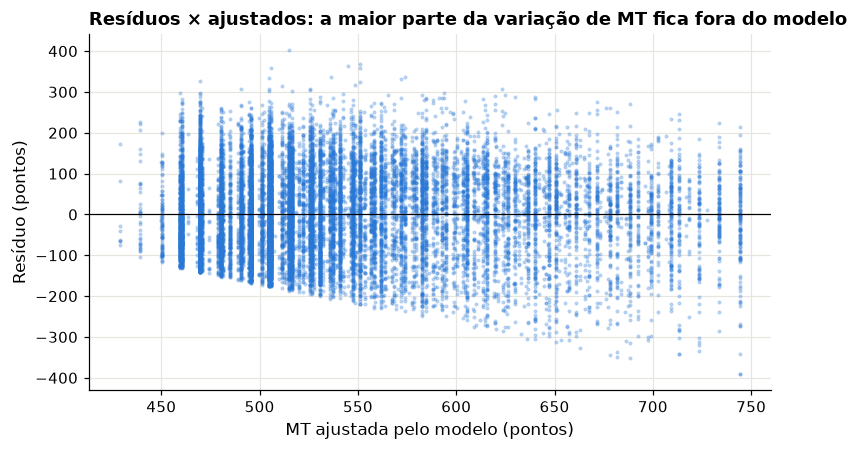

In [68]:
# Verificação independente: codificação, VIF e resíduos × ajustados
vars_comp = ['renda', 'privada', 'mulher'] + COR_VARS
print('Cor/raça como indicadoras 0/1 (não como número 0–6):', bool(conc[COR_VARS].isin([0, 1]).all().all()))
Xc = sm.add_constant(conc[vars_comp]).to_numpy(dtype=float)
vif = pd.Series([variance_inflation_factor(Xc, i + 1) for i in range(len(vars_comp))], index=vars_comp)
display(vif.round(2).to_frame('VIF (acima de 10 indica colinearidade forte)'))

rng = np.random.default_rng(SEMENTE)          # gerador desta seção: 20 mil pontos para o gráfico
ii = rng.choice(len(conc), 20_000, replace=False)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(completo.fittedvalues.iloc[ii], completo.resid.iloc[ii], s=3, alpha=0.25, color=AZUL)
ax.axhline(0, color='black', lw=0.8)
ax.set_xlabel('MT ajustada pelo modelo (pontos)'); ax.set_ylabel('Resíduo (pontos)')
ax.set_title('Resíduos × ajustados: a maior parte da variação de MT fica fora do modelo')
plt.show()

**Leitura:** ao incluir o tipo de escola, o coeficiente da renda **cai**: parte da associação atribuída à renda era associação com a escola privada (renda e escola andam juntas, o **confundidor** do slide "correlação não é causa"). Por cor/raça (referência: brancos), as diferenças caem para cerca da metade com renda, escola e sexo no modelo: parte acompanha esses fatores e parte **permanece**. O que permanece **não** é "o efeito da cor": é a diferença que estas variáveis não explicam (território, qualidade da escola, discriminação e outros fatores não medidos). E o R² fica abaixo de 0,3: a maior parte da variação de MT está **dentro** dos grupos.

---
# Encerramento: checklist de relatório

Para cada resultado levado à diretoria:
1. **Pergunta e hipótese** escritas antes da análise (pré-registro).
2. **População** analisada e quem ficou de fora (nulos, zeros, filtros, presença).
3. **Plano amostral** e justificativa do n (precisão ou menor efeito relevante).
4. **Efeito + IC95% + valor-p + tamanho do efeito** (nunca só o valor-p).
5. **Leitura de relevância** com a margem definida antes (relevante / irrelevante / inconclusivo).
6. **Limitações:** delineamento observacional, confundidores, quem ficou fora da base.
7. **Registro de IA:** prompt, modelo, data e a verificação independente feita.

In [69]:
# Modelo de registro de uso de IA (regra 7): uma linha por prompt usado na análise
registro_ia = pd.DataFrame(columns=['data', 'ferramenta/modelo', 'seção do notebook', 'prompt (resumo)',
                                    'o que foi aproveitado', 'verificação independente feita', 'resultado da verificação'])
registro_ia

,data,ferramenta/modelo,seção do notebook,prompt (resumo),o que foi aproveitado,verificação independente feita,resultado da verificação
